In [106]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = '4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from utils.models import *
from utils.dataloader import *
from utils.utils_sig import *
from utils.Loss import *


# onebyone

In [107]:
def calculate_batch_mae(preds, targets, fs=30):
    
    mae_sum = 0.0
    valid_count = 0
    
    # GPU 텐서를 CPU 넘파이 배열로 변
    
    # 2. FFT 기반 HR 추출
    pred_hr, _, _ = hr_fft(preds, fs)
    gt_hr, _, _ = hr_fft(targets, fs)
    
    mae = abs(pred_hr - gt_hr)
            
    return mae

def z_norm_per_sample(x):
    # x: (B, T)
    mean = x.mean(dim=-1, keepdim=True)   # (B, 1)
    std  = x.std(dim=-1, keepdim=True)    # (B, 1)
    return (x - mean) / (std + 1e-8)      # per-sample


In [91]:
print(valid_files)

['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped_len300/final_dataset_C002_20250703.h5', '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped_len300/final_dataset_C003_20250702.h5']


In [153]:
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/MR-nirp_driving_motion_registration'
pic_save_dir = '/home/son/orientation-uv-rppg/data/pics'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")


# ===== 데이터 로드 및 추론 (10초 = 300프레임 단일 윈도우) =====
all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5')]
print(all_files)

모델 로드 완료
['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/MR-nirp_driving_motion_registration/subject10_driving_large_motion_975_uv.h5', '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/MR-nirp_driving_motion_registration/subject10_driving_small_motion_940_uv.h5', '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/MR-nirp_driving_motion_registration/subject10_driving_small_motion_975_uv.h5', '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/MR-nirp_driving_motion_registration/subject10_garage_large_motion_975_uv.h5', '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/MR-nirp_driving_motion_registration/subject10_garage_small_motion_940_uv.h5', '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/MR-nirp_driving_motion_registration/subject10_garage_small_motion_975_uv.h5', '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/MR-nirp_

모델 로드 완료
['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/driving_cropped_dl_data/subject4_garage_large_motion_975_dldata.h5']
rPPG: (300,), GT: (300,)


/tmp/ipykernel_3325155/3576085078.py:207: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



💾 Saved: /home/son/orientation-uv-rppg/data/pics/time_freq_domain_10s_zeropad.png


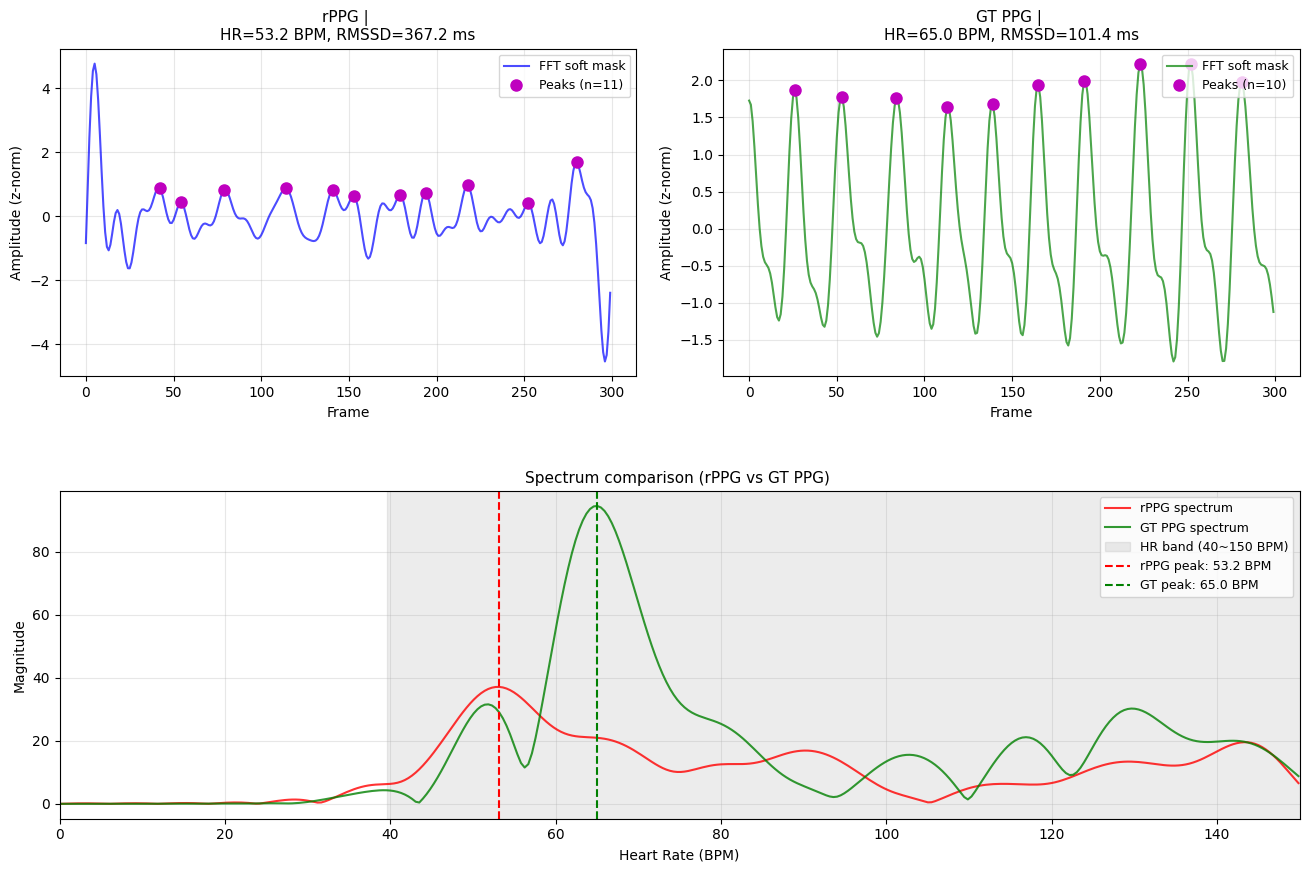


Metrics summary (10s window, nfft=4096)
BPM bin resolution: 0.439 BPM
HR (FFT+harmonic) | rPPG: 53.17 BPM, GT: 65.04 BPM, Error: 11.87 BPM
RMSSD (peak-based) | rPPG: 367.17 ms, GT: 101.38 ms, Ratio: 3.62x
# peaks (time-domain) | rPPG: 11, GT: 10


: 

In [159]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy import signal
from scipy.signal import butter, filtfilt
from scipy.fft import fft

# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/nirpdriving/LOSO_driving_cropped_ncorshift/fold_7/best_model.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/driving_cropped_dl_data'
pic_save_dir = '/home/son/orientation-uv-rppg/data/pics'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")


# ===== 데이터 로드 및 추론 (10초 = 300프레임 단일 윈도우) =====
all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5')]
valid_files = all_files[9:10]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

window_idx = 5

input_vid, gt_ppg, _ = valid_dataset[window_idx]
input_vid = input_vid.unsqueeze(0).to(device)
with torch.no_grad():
    rppg = model(input_vid)

rppg_np   = rppg.cpu().numpy().flatten().astype(np.float64)
gt_ppg_np = (gt_ppg.numpy() if hasattr(gt_ppg, 'numpy') else np.asarray(gt_ppg)).astype(np.float64)
print(f"rPPG: {rppg_np.shape}, GT: {gt_ppg_np.shape}")


# ===== Bandpass (soft FFT mask) =====
def bandpass_fft_soft(sig, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(sig, np.ndarray)
    if is_numpy:
        sig = torch.tensor(sig, dtype=torch.float32)
    N = sig.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(sig.device)
    fft_signal = torch.fft.rfft(sig)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    filtered = torch.fft.irfft(fft_signal * mask, n=N)
    return filtered.cpu().numpy() if is_numpy else filtered


# ===== Zero-padding FFT 기반 HR + PSD (Contrast-Phys+ 스타일) =====
def hr_fft(sig, fs, harmonics_removal=False, lowcut=0.66, highcut=2.5, nfft=None):
    """
    Zero-padding FFT로 HR 추정. PSD plot용 spectrum과 BPM 축도 함께 반환.
    Returns:
        hr      : 추정 HR (BPM)
        sig_f   : original magnitude spectrum (band masking 전 — plot용)
        x_hr    : BPM 단위 frequency 축
        peak_bpm: HR band 내 dominant peak BPM (vline용)
    """
    sig = sig.reshape(-1)
    N = sig.shape[0]
    sig = sig * signal.windows.hann(N)  # spectral leakage 감소
    
    # zero-padding: 기본 4096 (10초 @ 30fps → 300pt → 4096pt = ~13.6x oversampling)
    # → bin resolution 0.1 Hz(6 BPM) → 30/4096 Hz ≈ 0.44 BPM
    if nfft is None:
        nfft = max(4096, N)
    
    sig_f = np.abs(fft(sig, n=nfft))
    
    # HR band index
    low_idx  = np.round(lowcut  / fs * nfft).astype('int')
    high_idx = np.round(highcut / fs * nfft).astype('int')
    
    # plot용 원본 보존, peak 찾기용 masked
    sig_f_original = sig_f.copy()
    sig_f_masked   = sig_f.copy()
    sig_f_masked[:low_idx]  = 0
    sig_f_masked[high_idx:] = 0
    
    # peak 검출
    peak_idx, _ = signal.find_peaks(sig_f_masked)
    x_hr = np.arange(nfft) / nfft * fs * 60  # BPM axis
    
    if len(peak_idx) == 0:
        return np.nan, sig_f_original, x_hr, np.nan
    
    if len(peak_idx) == 1:
        hr = peak_idx[0] / nfft * fs * 60
        return hr, sig_f_original, x_hr, hr
    
    # 상위 2개 peak으로 harmonic 판별
    sort_idx = np.argsort(sig_f_masked[peak_idx])[::-1]
    peak_idx1 = peak_idx[sort_idx[0]]
    peak_idx2 = peak_idx[sort_idx[1]]
    hr1 = peak_idx1 / nfft * fs * 60
    hr2 = peak_idx2 / nfft * fs * 60
    
    if harmonics_removal:
        # hr1이 hr2의 2배(2차 harmonic)에 가까우면 hr2(fundamental)가 진짜
        if np.abs(hr1 - 2 * hr2) < 10:
            hr = hr2
        else:
            hr = hr1
    else:
        hr = hr1
    
    return hr, sig_f_original, x_hr, hr


# ===== peak detection (time-domain plot용, RMSSD 계산용) =====
def compute_rmssd_only(sig, fs=30):
    """time-domain peak detection으로 RMSSD만 계산. HR은 별도로 FFT 기반 사용."""
    try:
        clean = nk.ppg_clean(sig.copy(), sampling_rate=fs, method='elgendi')
        peaks = nk.ppg_findpeaks(clean, sampling_rate=fs)["PPG_Peaks"]
        if len(peaks) < 3:
            return None, peaks
        ibi_ms = (peaks[1:] - peaks[:-1]) / fs * 1000
        d = np.diff(ibi_ms)
        return {
            'rmssd_ms':  np.sqrt(np.mean(d**2)),
            'num_peaks': len(peaks),
        }, peaks
    except Exception as e:
        print(f"⚠️ peak detection failed: {e}")
        return None, np.array([])


# ===== 필터 적용 + z-norm =====
fs = 30
NFFT = 4096  # zero-padding bin 수

rppg_fft = bandpass_fft_soft(rppg_np, fs=fs)
rppg_fft = (rppg_fft - np.mean(rppg_fft)) / np.std(rppg_fft)
gt_use   = gt_ppg_np.copy()

# ===== HR (FFT 기반) =====
hr_rppg, spec_rppg, bpm_axis_rppg, peak_bpm_rppg = hr_fft(rppg_fft, fs=fs, nfft=NFFT)
hr_gt,   spec_gt,   bpm_axis_gt,   peak_bpm_gt   = hr_fft(gt_use,   fs=fs, nfft=NFFT)

# ===== RMSSD (peak detection 기반) =====
rppg_rmssd_info, rppg_peaks = compute_rmssd_only(rppg_fft, fs=fs)
gt_rmssd_info,   gt_peaks   = compute_rmssd_only(gt_use,   fs=fs)

rppg_rmssd = rppg_rmssd_info['rmssd_ms'] if rppg_rmssd_info else np.nan
gt_rmssd   = gt_rmssd_info['rmssd_ms']   if gt_rmssd_info   else np.nan


# ===== 시각화 =====
frames = np.arange(len(rppg_fft))

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.15)

# (0, 0): rPPG time domain + peaks (RMSSD용 marker)
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(frames, rppg_fft, 'b-', alpha=0.7, label='FFT soft mask')
if len(rppg_peaks) > 0:
    ax1.plot(rppg_peaks, rppg_fft[rppg_peaks], 'mo',
             markersize=8, label=f'Peaks (n={len(rppg_peaks)})')
title = f'rPPG | \nHR={hr_rppg:.1f} BPM, RMSSD={rppg_rmssd:.1f} ms'
ax1.set_title(title, fontsize=11)
ax1.set_xlabel('Frame'); ax1.set_ylabel('Amplitude (z-norm)')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)

# (0, 1): GT time domain + peaks
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(frames, gt_use, 'g-', alpha=0.7, label='FFT soft mask')
if len(gt_peaks) > 0:
    ax2.plot(gt_peaks, gt_use[gt_peaks], 'mo',
             markersize=8, label=f'Peaks (n={len(gt_peaks)})')
title = f'GT PPG | \nHR={hr_gt:.1f} BPM, RMSSD={gt_rmssd:.1f} ms'
ax2.set_title(title, fontsize=11)
ax2.set_xlabel('Frame'); ax2.set_ylabel('Amplitude (z-norm)')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)

# (1, :): PSD (zero-padded) overlay - x축 BPM
ax3 = fig.add_subplot(gs[1, :])
# HR band 범위만 표시 (0~150 BPM 정도)
plot_mask = bpm_axis_rppg <= 150
ax3.plot(bpm_axis_rppg[plot_mask], spec_rppg[plot_mask],
         color='red',   label='rPPG spectrum', alpha=0.8)
ax3.plot(bpm_axis_gt[plot_mask],   spec_gt[plot_mask],
         color='green', label='GT PPG spectrum', alpha=0.8)
ax3.axvspan(0.66*60, 2.5*60, color='gray', alpha=0.15,
            label='HR band (40~150 BPM)')
ax3.axvline(hr_rppg, color='red',   linestyle='--', linewidth=1.5,
            label=f'rPPG peak: {hr_rppg:.1f} BPM')
ax3.axvline(hr_gt,   color='green', linestyle='--', linewidth=1.5,
            label=f'GT peak: {hr_gt:.1f} BPM')

ax3.set_xlim(0, 150)
ax3.set_title(f'Spectrum comparison (rPPG vs GT PPG) '
              , fontsize=11)
ax3.set_xlabel('Heart Rate (BPM)')
ax3.set_ylabel('Magnitude')
ax3.legend(loc='upper right', fontsize=9)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
save_path = os.path.join(pic_save_dir, 'time_freq_domain_10s_zeropad.png')
plt.savefig(save_path, dpi=120, bbox_inches='tight')
print(f"\n💾 Saved: {save_path}")
plt.show()


# ===== 메트릭 출력 =====
print("\n" + "="*60)
print(f"Metrics summary (10s window, nfft={NFFT})")
print(f"BPM bin resolution: {fs/NFFT*60:.3f} BPM")
print("="*60)
print(f"HR (FFT+harmonic) | rPPG: {hr_rppg:.2f} BPM, GT: {hr_gt:.2f} BPM, "
      f"Error: {abs(hr_rppg - hr_gt):.2f} BPM")
print(f"RMSSD (peak-based) | rPPG: {rppg_rmssd:.2f} ms, GT: {gt_rmssd:.2f} ms, "
      f"Ratio: {rppg_rmssd/gt_rmssd:.2f}x")
print(f"# peaks (time-domain) | rPPG: {len(rppg_peaks)}, GT: {len(gt_peaks)}")

모델 로드 완료
['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped_len300/final_dataset_C003_20250702.h5']
rPPG: (300,), GT: (300,)


/tmp/ipykernel_3325155/208572230.py:207: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



💾 Saved: /home/son/orientation-uv-rppg/data/pics/time_freq_domain_10s_zeropad.png


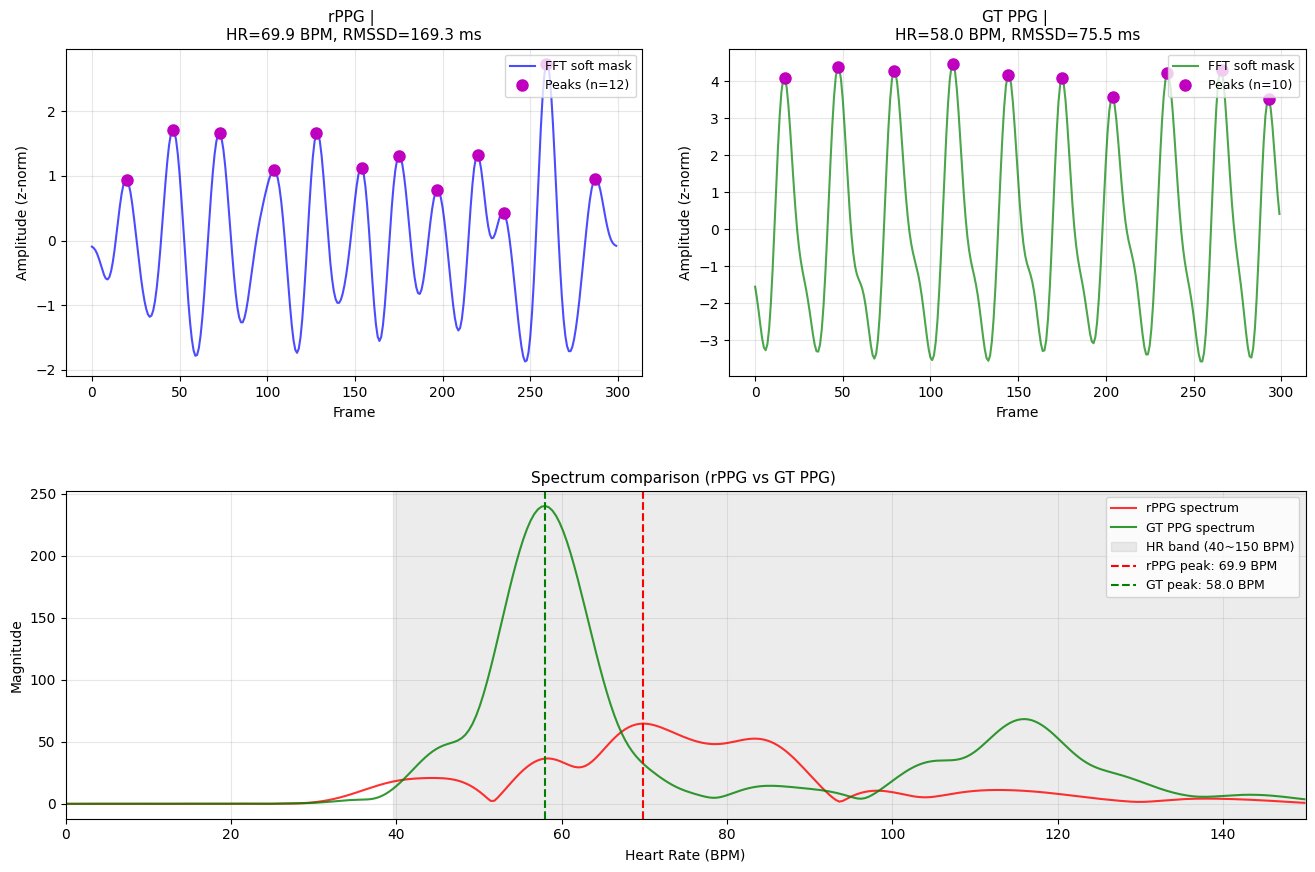


Metrics summary (10s window, nfft=4096)
BPM bin resolution: 0.439 BPM
HR (FFT+harmonic) | rPPG: 69.87 BPM, GT: 58.01 BPM, Error: 11.87 BPM
RMSSD (peak-based) | rPPG: 169.31 ms, GT: 75.46 ms, Ratio: 2.24x
# peaks (time-domain) | rPPG: 12, GT: 10


In [132]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy import signal
from scipy.signal import butter, filtfilt
from scipy.fft import fft

# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/300franewithoutregis/klloss+ncorshift/0.0001_epoch:18_MAE: 10.94.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped_len300'
pic_save_dir = '/home/son/orientation-uv-rppg/data/pics'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")


# ===== 데이터 로드 및 추론 (10초 = 300프레임 단일 윈도우) =====
all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5')]
valid_files = all_files[14:]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

window_idx = 0

input_vid, gt_ppg, _ = valid_dataset[window_idx]
input_vid = input_vid.unsqueeze(0).to(device)
with torch.no_grad():
    rppg = model(input_vid)

rppg_np   = rppg.cpu().numpy().flatten().astype(np.float64)
gt_ppg_np = (gt_ppg.numpy() if hasattr(gt_ppg, 'numpy') else np.asarray(gt_ppg)).astype(np.float64)
print(f"rPPG: {rppg_np.shape}, GT: {gt_ppg_np.shape}")


# ===== Bandpass (soft FFT mask) =====
def bandpass_fft_soft(sig, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(sig, np.ndarray)
    if is_numpy:
        sig = torch.tensor(sig, dtype=torch.float32)
    N = sig.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(sig.device)
    fft_signal = torch.fft.rfft(sig)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    filtered = torch.fft.irfft(fft_signal * mask, n=N)
    return filtered.cpu().numpy() if is_numpy else filtered


# ===== Zero-padding FFT 기반 HR + PSD (Contrast-Phys+ 스타일) =====
def hr_fft(sig, fs, harmonics_removal=False, lowcut=0.66, highcut=2.5, nfft=None):
    """
    Zero-padding FFT로 HR 추정. PSD plot용 spectrum과 BPM 축도 함께 반환.
    Returns:
        hr      : 추정 HR (BPM)
        sig_f   : original magnitude spectrum (band masking 전 — plot용)
        x_hr    : BPM 단위 frequency 축
        peak_bpm: HR band 내 dominant peak BPM (vline용)
    """
    sig = sig.reshape(-1)
    N = sig.shape[0]
    sig = sig * signal.windows.hann(N)  # spectral leakage 감소
    
    # zero-padding: 기본 4096 (10초 @ 30fps → 300pt → 4096pt = ~13.6x oversampling)
    # → bin resolution 0.1 Hz(6 BPM) → 30/4096 Hz ≈ 0.44 BPM
    if nfft is None:
        nfft = max(4096, N)
    
    sig_f = np.abs(fft(sig, n=nfft))
    
    # HR band index
    low_idx  = np.round(lowcut  / fs * nfft).astype('int')
    high_idx = np.round(highcut / fs * nfft).astype('int')
    
    # plot용 원본 보존, peak 찾기용 masked
    sig_f_original = sig_f.copy()
    sig_f_masked   = sig_f.copy()
    sig_f_masked[:low_idx]  = 0
    sig_f_masked[high_idx:] = 0
    
    # peak 검출
    peak_idx, _ = signal.find_peaks(sig_f_masked)
    x_hr = np.arange(nfft) / nfft * fs * 60  # BPM axis
    
    if len(peak_idx) == 0:
        return np.nan, sig_f_original, x_hr, np.nan
    
    if len(peak_idx) == 1:
        hr = peak_idx[0] / nfft * fs * 60
        return hr, sig_f_original, x_hr, hr
    
    # 상위 2개 peak으로 harmonic 판별
    sort_idx = np.argsort(sig_f_masked[peak_idx])[::-1]
    peak_idx1 = peak_idx[sort_idx[0]]
    peak_idx2 = peak_idx[sort_idx[1]]
    hr1 = peak_idx1 / nfft * fs * 60
    hr2 = peak_idx2 / nfft * fs * 60
    
    if harmonics_removal:
        # hr1이 hr2의 2배(2차 harmonic)에 가까우면 hr2(fundamental)가 진짜
        if np.abs(hr1 - 2 * hr2) < 10:
            hr = hr2
        else:
            hr = hr1
    else:
        hr = hr1
    
    return hr, sig_f_original, x_hr, hr


# ===== peak detection (time-domain plot용, RMSSD 계산용) =====
def compute_rmssd_only(sig, fs=30):
    """time-domain peak detection으로 RMSSD만 계산. HR은 별도로 FFT 기반 사용."""
    try:
        clean = nk.ppg_clean(sig.copy(), sampling_rate=fs, method='elgendi')
        peaks = nk.ppg_findpeaks(clean, sampling_rate=fs)["PPG_Peaks"]
        if len(peaks) < 3:
            return None, peaks
        ibi_ms = (peaks[1:] - peaks[:-1]) / fs * 1000
        d = np.diff(ibi_ms)
        return {
            'rmssd_ms':  np.sqrt(np.mean(d**2)),
            'num_peaks': len(peaks),
        }, peaks
    except Exception as e:
        print(f"⚠️ peak detection failed: {e}")
        return None, np.array([])


# ===== 필터 적용 + z-norm =====
fs = 30
NFFT = 4096  # zero-padding bin 수

rppg_fft = bandpass_fft_soft(rppg_np, fs=fs)
rppg_fft = (rppg_fft - np.mean(rppg_fft)) / np.std(rppg_fft)
gt_use   = gt_ppg_np.copy()

# ===== HR (FFT 기반) =====
hr_rppg, spec_rppg, bpm_axis_rppg, peak_bpm_rppg = hr_fft(rppg_fft, fs=fs, nfft=NFFT)
hr_gt,   spec_gt,   bpm_axis_gt,   peak_bpm_gt   = hr_fft(gt_use,   fs=fs, nfft=NFFT)

# ===== RMSSD (peak detection 기반) =====
rppg_rmssd_info, rppg_peaks = compute_rmssd_only(rppg_fft, fs=fs)
gt_rmssd_info,   gt_peaks   = compute_rmssd_only(gt_use,   fs=fs)

rppg_rmssd = rppg_rmssd_info['rmssd_ms'] if rppg_rmssd_info else np.nan
gt_rmssd   = gt_rmssd_info['rmssd_ms']   if gt_rmssd_info   else np.nan


# ===== 시각화 =====
frames = np.arange(len(rppg_fft))

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.15)

# (0, 0): rPPG time domain + peaks (RMSSD용 marker)
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(frames, rppg_fft, 'b-', alpha=0.7, label='FFT soft mask')
if len(rppg_peaks) > 0:
    ax1.plot(rppg_peaks, rppg_fft[rppg_peaks], 'mo',
             markersize=8, label=f'Peaks (n={len(rppg_peaks)})')
title = f'rPPG | \nHR={hr_rppg:.1f} BPM, RMSSD={rppg_rmssd:.1f} ms'
ax1.set_title(title, fontsize=11)
ax1.set_xlabel('Frame'); ax1.set_ylabel('Amplitude (z-norm)')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)

# (0, 1): GT time domain + peaks
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(frames, gt_use, 'g-', alpha=0.7, label='FFT soft mask')
if len(gt_peaks) > 0:
    ax2.plot(gt_peaks, gt_use[gt_peaks], 'mo',
             markersize=8, label=f'Peaks (n={len(gt_peaks)})')
title = f'GT PPG | \nHR={hr_gt:.1f} BPM, RMSSD={gt_rmssd:.1f} ms'
ax2.set_title(title, fontsize=11)
ax2.set_xlabel('Frame'); ax2.set_ylabel('Amplitude (z-norm)')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)

# (1, :): PSD (zero-padded) overlay - x축 BPM
ax3 = fig.add_subplot(gs[1, :])
# HR band 범위만 표시 (0~150 BPM 정도)
plot_mask = bpm_axis_rppg <= 150
ax3.plot(bpm_axis_rppg[plot_mask], spec_rppg[plot_mask],
         color='red',   label='rPPG spectrum', alpha=0.8)
ax3.plot(bpm_axis_gt[plot_mask],   spec_gt[plot_mask],
         color='green', label='GT PPG spectrum', alpha=0.8)
ax3.axvspan(0.66*60, 2.5*60, color='gray', alpha=0.15,
            label='HR band (40~150 BPM)')
ax3.axvline(hr_rppg, color='red',   linestyle='--', linewidth=1.5,
            label=f'rPPG peak: {hr_rppg:.1f} BPM')
ax3.axvline(hr_gt,   color='green', linestyle='--', linewidth=1.5,
            label=f'GT peak: {hr_gt:.1f} BPM')

ax3.set_xlim(0, 150)
ax3.set_title(f'Spectrum comparison (rPPG vs GT PPG) '
              , fontsize=11)
ax3.set_xlabel('Heart Rate (BPM)')
ax3.set_ylabel('Magnitude')
ax3.legend(loc='upper right', fontsize=9)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
save_path = os.path.join(pic_save_dir, 'time_freq_domain_10s_zeropad.png')
plt.savefig(save_path, dpi=120, bbox_inches='tight')
print(f"\n💾 Saved: {save_path}")
plt.show()


# ===== 메트릭 출력 =====
print("\n" + "="*60)
print(f"Metrics summary (10s window, nfft={NFFT})")
print(f"BPM bin resolution: {fs/NFFT*60:.3f} BPM")
print("="*60)
print(f"HR (FFT+harmonic) | rPPG: {hr_rppg:.2f} BPM, GT: {hr_gt:.2f} BPM, "
      f"Error: {abs(hr_rppg - hr_gt):.2f} BPM")
print(f"RMSSD (peak-based) | rPPG: {rppg_rmssd:.2f} ms, GT: {gt_rmssd:.2f} ms, "
      f"Ratio: {rppg_rmssd/gt_rmssd:.2f}x")
print(f"# peaks (time-domain) | rPPG: {len(rppg_peaks)}, GT: {len(gt_peaks)}")

In [109]:
# ===== 전체 valid_dataset에 대한 MAE 계산 =====
print("\n" + "="*60)
print(f"Computing metrics over all {len(valid_dataset)} windows...")
print("="*60)

all_hr_rppg, all_hr_gt = [], []
all_rmssd_rppg, all_rmssd_gt = [], []
valid_indices = []  # 실제로 성공한 윈도우의 원래 인덱스 저장
skipped = 0

for i in range(len(valid_dataset)):
    try:
        input_vid_i, gt_ppg_i, _ = valid_dataset[i]
        input_vid_i = input_vid_i.unsqueeze(0).to(device)
        with torch.no_grad():
            rppg_i = model(input_vid_i)
        rppg_i_np = rppg_i.cpu().numpy().flatten().astype(np.float64)
        gt_i_np = (gt_ppg_i.numpy() if hasattr(gt_ppg_i, 'numpy')
                   else np.asarray(gt_ppg_i)).astype(np.float64)

        # 필터 + z-norm
        rppg_i_fft = bandpass_fft_soft(rppg_i_np, fs=fs)
        rppg_i_fft = (rppg_i_fft - np.mean(rppg_i_fft)) / np.std(rppg_i_fft)

        # HR (FFT 기반)
        hr_r, _, _, _ = hr_fft(rppg_i_fft, fs=fs, nfft=NFFT)
        hr_g, _, _, _ = hr_fft(gt_i_np,    fs=fs, nfft=NFFT)

        # RMSSD (peak detection 기반)
        rppg_rmssd_i, _ = compute_rmssd_only(rppg_i_fft, fs=fs)
        gt_rmssd_i,   _ = compute_rmssd_only(gt_i_np,    fs=fs)

        if np.isnan(hr_r) or np.isnan(hr_g) or rppg_rmssd_i is None or gt_rmssd_i is None:
            skipped += 1
            continue

        all_hr_rppg.append(hr_r)
        all_hr_gt.append(hr_g)
        all_rmssd_rppg.append(rppg_rmssd_i['rmssd_ms'])
        all_rmssd_gt.append(gt_rmssd_i['rmssd_ms'])
        valid_indices.append(i)
    except Exception as e:
        print(f"  ⚠️ window {i} failed: {e}")
        skipped += 1

# numpy 변환
all_hr_rppg = np.array(all_hr_rppg)
all_hr_gt = np.array(all_hr_gt)
all_rmssd_rppg = np.array(all_rmssd_rppg)
all_rmssd_gt = np.array(all_rmssd_gt)
valid_indices = np.array(valid_indices)

# 윈도우별 절대 오차
hr_errors    = np.abs(all_hr_rppg - all_hr_gt)
rmssd_errors = np.abs(all_rmssd_rppg - all_rmssd_gt)

# 메트릭 계산
hr_mae      = np.mean(hr_errors)
hr_rmse     = np.sqrt(np.mean((all_hr_rppg - all_hr_gt)**2))
rmssd_mae   = np.mean(rmssd_errors)
rmssd_rmse  = np.sqrt(np.mean((all_rmssd_rppg - all_rmssd_gt)**2))
rmssd_mape  = np.mean(rmssd_errors / all_rmssd_gt) * 100
hr_pearson    = np.corrcoef(all_hr_rppg, all_hr_gt)[0, 1]
rmssd_pearson = np.corrcoef(all_rmssd_rppg, all_rmssd_gt)[0, 1]

# Best / Worst 인덱스 (원본 valid_dataset 인덱스로 변환)
hr_worst_pos    = np.argmax(hr_errors)
hr_best_pos     = np.argmin(hr_errors)
rmssd_worst_pos = np.argmax(rmssd_errors)
rmssd_best_pos  = np.argmin(rmssd_errors)

hr_worst_idx    = valid_indices[hr_worst_pos]
hr_best_idx     = valid_indices[hr_best_pos]
rmssd_worst_idx = valid_indices[rmssd_worst_pos]
rmssd_best_idx  = valid_indices[rmssd_best_pos]

print(f"\nValid windows: {len(all_hr_rppg)} / {len(valid_dataset)} (skipped: {skipped})")
print(f"\n[HR]")
print(f"  MAE       : {hr_mae:.2f} BPM")
print(f"  RMSE      : {hr_rmse:.2f} BPM")
print(f"  Pearson r : {hr_pearson:.3f}")
print(f"  Worst idx : {hr_worst_idx} (error={hr_errors[hr_worst_pos]:.2f} BPM, "
      f"rPPG={all_hr_rppg[hr_worst_pos]:.1f}, GT={all_hr_gt[hr_worst_pos]:.1f})")
print(f"  Best  idx : {hr_best_idx} (error={hr_errors[hr_best_pos]:.2f} BPM, "
      f"rPPG={all_hr_rppg[hr_best_pos]:.1f}, GT={all_hr_gt[hr_best_pos]:.1f})")

print(f"\n[RMSSD]")
print(f"  MAE       : {rmssd_mae:.2f} ms")
print(f"  RMSE      : {rmssd_rmse:.2f} ms")
print(f"  MAPE      : {rmssd_mape:.1f} %")
print(f"  Pearson r : {rmssd_pearson:.3f}")
print(f"  rPPG mean : {np.mean(all_rmssd_rppg):.1f} ms")
print(f"  GT mean   : {np.mean(all_rmssd_gt):.1f} ms")
print(f"  Ratio     : {np.mean(all_rmssd_rppg)/np.mean(all_rmssd_gt):.2f}x")
print(f"  Worst idx : {rmssd_worst_idx} (error={rmssd_errors[rmssd_worst_pos]:.2f} ms, "
      f"rPPG={all_rmssd_rppg[rmssd_worst_pos]:.1f}, GT={all_rmssd_gt[rmssd_worst_pos]:.1f})")
print(f"  Best  idx : {rmssd_best_idx} (error={rmssd_errors[rmssd_best_pos]:.2f} ms, "
      f"rPPG={all_rmssd_rppg[rmssd_best_pos]:.1f}, GT={all_rmssd_gt[rmssd_best_pos]:.1f})")

# 추가 옵션: mean error에 가장 가까운 윈도우
hr_mean_pos = np.argmin(np.abs(hr_errors - hr_mae))
hr_mean_idx = valid_indices[hr_mean_pos]
print(f"  Mean-MAE idx : {hr_mean_idx} (error={hr_errors[hr_mean_pos]:.2f} BPM)")


Computing metrics over all 99 windows...

Valid windows: 99 / 99 (skipped: 0)

[HR]
  MAE       : 11.55 BPM
  RMSE      : 14.46 BPM
  Pearson r : -0.174
  Worst idx : 80 (error=36.91 BPM, rPPG=55.4, GT=92.3)
  Best  idx : 14 (error=0.00 BPM, rPPG=70.8, GT=70.8)

[RMSSD]
  MAE       : 179.57 ms
  RMSE      : 194.38 ms
  MAPE      : 379.7 %
  Pearson r : 0.010
  rPPG mean : 233.0 ms
  GT mean   : 53.9 ms
  Ratio     : 4.32x
  Worst idx : 5 (error=371.88 ms, rPPG=405.2, GT=33.3)
  Best  idx : 0 (error=18.88 ms, rPPG=202.0, GT=183.1)
  Mean-MAE idx : 25 (error=11.87 BPM)


In [111]:
import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy import signal
from scipy.signal import butter, filtfilt
from scipy.fft import fft

shifts = np.load('/home/son/orientation-uv-rppg/data/shift_list_save/CNA_data/with_regis_900frmae_bandpassbeforelosscompute_negcorshift/best_val_shifts_41.npy')
print(shifts.shape)
shift_1 = shifts[2]
print(shift_1)

# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/300franewithregis_13out_and_znorm/ncor_withoutshift/0.0001_epoch:80_MAE: 9.80.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier_len300'
pic_save_dir = '/home/son/orientation-uv-rppg/data/pics'

base_model = ViT_ST_ST_Compact3_TDC_gra_sharp(
    image_size=(300, 64, 64),
    patches=(4, 4, 4),
    in_channels=1,
    theta=0.2
)

class PhysFormerWrapper(nn.Module):
    def __init__(self, base_model, gra_sharp=2.0):
        super().__init__()
        self.model = base_model
        self.gra_sharp = gra_sharp

    def forward(self, x):
        rPPG, _, _, _ = self.model(x, self.gra_sharp)
        return rPPG

model = PhysFormerWrapper(base_model).to(device)
state_dict = torch.load(pth_path, map_location='cpu')
model.load_state_dict(state_dict)
model.to(device)
del state_dict
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 및 추론 =====
all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5')]
valid_files = all_files[13:14]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

window_idx = 25

input_vid, gt_ppg, _ = valid_dataset[window_idx]
input_vid = input_vid.unsqueeze(0).to(device)

with torch.no_grad():
    rppg = model(input_vid)

rppg_np = rppg.cpu().numpy().flatten().astype(np.float64)
gt_ppg_np = (gt_ppg.numpy() if hasattr(gt_ppg, 'numpy') else np.asarray(gt_ppg)).astype(np.float64)
print(f"rPPG: {rppg_np.shape}, GT: {gt_ppg_np.shape}")


# ===== Bandpass (soft FFT mask) =====
def bandpass_fft_soft(sig, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(sig, np.ndarray)
    if is_numpy:
        sig = torch.tensor(sig, dtype=torch.float32)
    N = sig.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(sig.device)
    fft_signal = torch.fft.rfft(sig)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    filtered = torch.fft.irfft(fft_signal * mask, n=N)
    return filtered.cpu().numpy() if is_numpy else filtered


# ===== Zero-padding FFT 기반 HR + spectrum (Contrast-Phys+ 스타일) =====
def hr_fft(sig, fs, harmonics_removal=True, lowcut=0.66, highcut=2.5, nfft=None):
    """
    Zero-padding FFT로 HR 추정. spectrum과 BPM 축도 함께 반환.
    """
    sig = sig.reshape(-1)
    N = sig.shape[0]
    sig = sig * signal.windows.hann(N)

    if nfft is None:
        nfft = max(4096, N)

    sig_f = np.abs(fft(sig, n=nfft))

    low_idx  = np.round(lowcut  / fs * nfft).astype('int')
    high_idx = np.round(highcut / fs * nfft).astype('int')

    sig_f_original = sig_f.copy()
    sig_f_masked = sig_f.copy()
    sig_f_masked[:low_idx]  = 0
    sig_f_masked[high_idx:] = 0

    peak_idx, _ = signal.find_peaks(sig_f_masked)
    x_hr = np.arange(nfft) / nfft * fs * 60

    if len(peak_idx) == 0:
        return np.nan, sig_f_original, x_hr

    if len(peak_idx) == 1:
        hr = peak_idx[0] / nfft * fs * 60
        return hr, sig_f_original, x_hr

    sort_idx = np.argsort(sig_f_masked[peak_idx])[::-1]
    peak_idx1 = peak_idx[sort_idx[0]]
    peak_idx2 = peak_idx[sort_idx[1]]
    hr1 = peak_idx1 / nfft * fs * 60
    hr2 = peak_idx2 / nfft * fs * 60

    if harmonics_removal:
        if np.abs(hr1 - 2 * hr2) < 10:
            hr = hr2
        else:
            hr = hr1
    else:
        hr = hr1

    return hr, sig_f_original, x_hr


# ===== peak detection (time-domain plot용, RMSSD 계산용) =====
def compute_rmssd_only(sig, fs=30):
    try:
        clean = nk.ppg_clean(sig.copy(), sampling_rate=fs, method='elgendi')
        peaks = nk.ppg_findpeaks(clean, sampling_rate=fs)["PPG_Peaks"]
        if len(peaks) < 3:
            return None, peaks
        ibi_ms = (peaks[1:] - peaks[:-1]) / fs * 1000
        d = np.diff(ibi_ms)
        return {
            'rmssd_ms':  np.sqrt(np.mean(d**2)),
            'num_peaks': len(peaks),
        }, peaks
    except Exception as e:
        print(f"⚠️ peak detection failed: {e}")
        return None, np.array([])


# ===== Loss (Pearson correlation) — 기존 함수 활용 =====
ncor = Neg_Pearson()

def get_cor_sliced(rppg, ppg, window_num):
    signal_size = rppg.shape[-1]
    window_size = signal_size // window_num
    cor_list = []
    for i in range(0, window_num):
        rppg_sliced = rppg[i*window_size : (i+1)*window_size].unsqueeze(0)
        ppg_sliced = ppg[i*window_size : (i+1)*window_size].unsqueeze(0)
        cor_list.append(ncor(rppg_sliced, ppg_sliced).item())
    ncor_mean = sum(cor_list) / window_num
    ncor_whole = ncor(rppg.unsqueeze(0), ppg.unsqueeze(0)).item()
    return cor_list, ncor_mean, ncor_whole


# ===== 필터 적용 + z-norm =====
fs = 30
NFFT = 4096

rppg_fft = bandpass_fft_soft(rppg_np, fs=fs)
rppg_fft = (rppg_fft - np.mean(rppg_fft)) / np.std(rppg_fft)

gt_ppg_znorm = (gt_ppg_np - np.mean(gt_ppg_np)) / np.std(gt_ppg_np)

# ===== HR (zero-padded FFT + harmonic removal) =====
hr_rppg, spec_rppg, bpm_axis_rppg = hr_fft(rppg_fft,     fs=fs, nfft=NFFT)
hr_gt,   spec_gt,   bpm_axis_gt   = hr_fft(gt_ppg_znorm, fs=fs, nfft=NFFT)

# ===== RMSSD (peak detection 기반) =====
rppg_rmssd_info, rppg_peaks = compute_rmssd_only(rppg_fft,     fs=fs)
gt_rmssd_info,   gt_peaks   = compute_rmssd_only(gt_ppg_znorm, fs=fs)

rppg_rmssd = rppg_rmssd_info['rmssd_ms'] if rppg_rmssd_info else np.nan
gt_rmssd   = gt_rmssd_info['rmssd_ms']   if gt_rmssd_info   else np.nan


# ===== 시각화 =====
frames = np.arange(len(rppg_fft))

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.15)

# (0, 0): rPPG time domain + peaks
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(frames, rppg_fft, 'b-', alpha=0.7, label='FFT soft mask')
if len(rppg_peaks) > 0:
    ax1.plot(rppg_peaks, rppg_fft[rppg_peaks], 'mo',
             markersize=8, label=f'Peaks (n={len(rppg_peaks)})')
title = f'rPPG | \nHR={hr_rppg:.1f} BPM, RMSSD={rppg_rmssd:.1f} ms'
ax1.set_title(title, fontsize=11)
ax1.set_xlabel('Frame'); ax1.set_ylabel('Amplitude (z-norm)')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)

# (0, 1): GT time domain + peaks
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(frames, gt_ppg_znorm, 'g-', alpha=0.7, label='FFT soft mask')
if len(gt_peaks) > 0:
    ax2.plot(gt_peaks, gt_ppg_znorm[gt_peaks], 'mo',
             markersize=8, label=f'Peaks (n={len(gt_peaks)})')
title = f'GT PPG | \nHR={hr_gt:.1f} BPM, RMSSD={gt_rmssd:.1f} ms'
ax2.set_title(title, fontsize=11)
ax2.set_xlabel('Frame'); ax2.set_ylabel('Amplitude (z-norm)')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)

# (1, :): Spectrum (zero-padded) overlay - x축 BPM
ax3 = fig.add_subplot(gs[1, :])
plot_mask = bpm_axis_rppg <= 150
ax3.plot(bpm_axis_rppg[plot_mask], spec_rppg[plot_mask],
         color='red',   label='rPPG spectrum', alpha=0.8)
ax3.plot(bpm_axis_gt[plot_mask],   spec_gt[plot_mask],
         color='green', label='GT PPG spectrum', alpha=0.8)
ax3.axvspan(0.66*60, 2.5*60, color='gray', alpha=0.15,
            label='HR band (40~150 BPM)')
ax3.axvline(hr_rppg, color='red',   linestyle='--', linewidth=1.5,
            label=f'rPPG peak: {hr_rppg:.1f} BPM')
ax3.axvline(hr_gt,   color='green', linestyle='--', linewidth=1.5,
            label=f'GT peak: {hr_gt:.1f} BPM')

ax3.set_xlim(0, 150)
ax3.set_title(f'Spectrum comparison (rPPG vs GT PPG) ', fontsize=11)
ax3.set_xlabel('Heart Rate (BPM)')
ax3.set_ylabel('Magnitude')
ax3.legend(loc='upper right', fontsize=9)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
save_path = os.path.join(pic_save_dir, 'physformer_time_freq_domain_10s_zeropad.png')
plt.savefig(save_path, dpi=120, bbox_inches='tight')
print(f"\n💾 Saved: {save_path}")
plt.show()


# ===== 메트릭 출력 =====
print("\n" + "="*60)
print(f"Metrics summary (PhysFormer, 10s window, nfft={NFFT})")
print(f"BPM bin resolution: {fs/NFFT*60:.3f} BPM")
print("="*60)
print(f"HR (FFT+harmonic) | rPPG: {hr_rppg:.2f} BPM, GT: {hr_gt:.2f} BPM, "
      f"Error: {abs(hr_rppg - hr_gt):.2f} BPM")
print(f"RMSSD (peak-based) | rPPG: {rppg_rmssd:.2f} ms, GT: {gt_rmssd:.2f} ms, "
      f"Ratio: {rppg_rmssd/gt_rmssd:.2f}x")
print(f"# peaks (time-domain) | rPPG: {len(rppg_peaks)}, GT: {len(gt_peaks)}")


# ===== Pearson loss 계산 (PhysFormer 평가용 유지) =====
rppg_tensor = torch.tensor(rppg_fft.copy(), dtype=torch.float32)
gt_tensor   = torch.tensor(gt_ppg_znorm.copy(), dtype=torch.float32)

cor_list, ncor_mean, ncor_whole = get_cor_sliced(rppg_tensor, gt_tensor, window_num=6)

print(f"\n전체 통째로 계산한 Loss: {ncor_whole:.4f}")
print(f"6조각으로 나누어 평균낸 Loss: {ncor_mean:.4f}")
print(f"각 조각별 Loss: {[round(c, 4) for c in cor_list]}")

(122,)
6


RuntimeError: Error(s) in loading state_dict for PhysFormerWrapper:
	Missing key(s) in state_dict: "model.patch_embedding.weight", "model.patch_embedding.bias", "model.transformer1.blocks.0.attn.proj_q.0.conv.weight", "model.transformer1.blocks.0.attn.proj_q.1.weight", "model.transformer1.blocks.0.attn.proj_q.1.bias", "model.transformer1.blocks.0.attn.proj_q.1.running_mean", "model.transformer1.blocks.0.attn.proj_q.1.running_var", "model.transformer1.blocks.0.attn.proj_k.0.conv.weight", "model.transformer1.blocks.0.attn.proj_k.1.weight", "model.transformer1.blocks.0.attn.proj_k.1.bias", "model.transformer1.blocks.0.attn.proj_k.1.running_mean", "model.transformer1.blocks.0.attn.proj_k.1.running_var", "model.transformer1.blocks.0.attn.proj_v.0.weight", "model.transformer1.blocks.0.proj.weight", "model.transformer1.blocks.0.proj.bias", "model.transformer1.blocks.0.norm1.weight", "model.transformer1.blocks.0.norm1.bias", "model.transformer1.blocks.0.pwff.fc1.0.weight", "model.transformer1.

# all

In [78]:
import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy import signal
from scipy.signal import butter, filtfilt
from scipy.fft import fft

shifts = np.load('/home/son/orientation-uv-rppg/data/shift_list_save/CNA_data/with_regis_900frmae_bandpassbeforelosscompute_negcorshift/best_val_shifts_41.npy')
print(shifts.shape)
shift_1 = shifts[2]
print(shift_1)

# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/physformer/300franewithregis_13out_and_znorm/bandpassbeforelosscompute_ncorshift/0.0001_epoch:86_MAE: 13.75.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier_len300'
pic_save_dir = '/home/son/orientation-uv-rppg/data/pics'

base_model = ViT_ST_ST_Compact3_TDC_gra_sharp(
    image_size=(300, 64, 64),
    patches=(4, 4, 4),
    in_channels=1,
    theta=0.2
)

class PhysFormerWrapper(nn.Module):
    def __init__(self, base_model, gra_sharp=2.0):
        super().__init__()
        self.model = base_model
        self.gra_sharp = gra_sharp

    def forward(self, x):
        rPPG, _, _, _ = self.model(x, self.gra_sharp)
        return rPPG

model = PhysFormerWrapper(base_model).to(device)
state_dict = torch.load(pth_path, map_location='cpu')
model.load_state_dict(state_dict)
model.to(device)
del state_dict
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 및 추론 =====
all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5')]
valid_files = all_files[13:14]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

window_idx = 29

input_vid, gt_ppg, _ = valid_dataset[window_idx]
input_vid = input_vid.unsqueeze(0).to(device)

with torch.no_grad():
    rppg = model(input_vid)

rppg_np = rppg.cpu().numpy().flatten().astype(np.float64)
gt_ppg_np = (gt_ppg.numpy() if hasattr(gt_ppg, 'numpy') else np.asarray(gt_ppg)).astype(np.float64)
print(f"rPPG: {rppg_np.shape}, GT: {gt_ppg_np.shape}")


# ===== Bandpass (soft FFT mask) =====
def bandpass_fft_soft(sig, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(sig, np.ndarray)
    if is_numpy:
        sig = torch.tensor(sig, dtype=torch.float32)
    N = sig.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(sig.device)
    fft_signal = torch.fft.rfft(sig)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    filtered = torch.fft.irfft(fft_signal * mask, n=N)
    return filtered.cpu().numpy() if is_numpy else filtered


# ===== Zero-padding FFT 기반 HR + spectrum (Contrast-Phys+ 스타일) =====
def hr_fft(sig, fs, harmonics_removal=True, lowcut=0.66, highcut=2.5, nfft=None):
    """
    Zero-padding FFT로 HR 추정. spectrum과 BPM 축도 함께 반환.
    """
    sig = sig.reshape(-1)
    N = sig.shape[0]
    sig = sig * signal.windows.hann(N)

    if nfft is None:
        nfft = max(4096, N)

    sig_f = np.abs(fft(sig, n=nfft))

    low_idx  = np.round(lowcut  / fs * nfft).astype('int')
    high_idx = np.round(highcut / fs * nfft).astype('int')

    sig_f_original = sig_f.copy()
    sig_f_masked = sig_f.copy()
    sig_f_masked[:low_idx]  = 0
    sig_f_masked[high_idx:] = 0

    peak_idx, _ = signal.find_peaks(sig_f_masked)
    x_hr = np.arange(nfft) / nfft * fs * 60

    if len(peak_idx) == 0:
        return np.nan, sig_f_original, x_hr

    if len(peak_idx) == 1:
        hr = peak_idx[0] / nfft * fs * 60
        return hr, sig_f_original, x_hr

    sort_idx = np.argsort(sig_f_masked[peak_idx])[::-1]
    peak_idx1 = peak_idx[sort_idx[0]]
    peak_idx2 = peak_idx[sort_idx[1]]
    hr1 = peak_idx1 / nfft * fs * 60
    hr2 = peak_idx2 / nfft * fs * 60

    if harmonics_removal:
        if np.abs(hr1 - 2 * hr2) < 10:
            hr = hr2
        else:
            hr = hr1
    else:
        hr = hr1

    return hr, sig_f_original, x_hr


# ===== peak detection (time-domain plot용, RMSSD 계산용) =====
def compute_rmssd_only(sig, fs=30):
    try:
        clean = nk.ppg_clean(sig.copy(), sampling_rate=fs, method='elgendi')
        peaks = nk.ppg_findpeaks(clean, sampling_rate=fs)["PPG_Peaks"]
        if len(peaks) < 3:
            return None, peaks
        ibi_ms = (peaks[1:] - peaks[:-1]) / fs * 1000
        d = np.diff(ibi_ms)
        return {
            'rmssd_ms':  np.sqrt(np.mean(d**2)),
            'num_peaks': len(peaks),
        }, peaks
    except Exception as e:
        print(f"⚠️ peak detection failed: {e}")
        return None, np.array([])


# ===== Loss (Pearson correlation) — 기존 함수 활용 =====
ncor = Neg_Pearson()

def get_cor_sliced(rppg, ppg, window_num):
    signal_size = rppg.shape[-1]
    window_size = signal_size // window_num
    cor_list = []
    for i in range(0, window_num):
        rppg_sliced = rppg[i*window_size : (i+1)*window_size].unsqueeze(0)
        ppg_sliced = ppg[i*window_size : (i+1)*window_size].unsqueeze(0)
        cor_list.append(ncor(rppg_sliced, ppg_sliced).item())
    ncor_mean = sum(cor_list) / window_num
    ncor_whole = ncor(rppg.unsqueeze(0), ppg.unsqueeze(0)).item()
    return cor_list, ncor_mean, ncor_whole


# ===== 필터 적용 + z-norm =====
fs = 30
NFFT = 4096

rppg_fft = bandpass_fft_soft(rppg_np, fs=fs)
rppg_fft = (rppg_fft - np.mean(rppg_fft)) / np.std(rppg_fft)

gt_ppg_znorm = (gt_ppg_np - np.mean(gt_ppg_np)) / np.std(gt_ppg_np)

# ===== HR (zero-padded FFT + harmonic removal) =====
hr_rppg, spec_rppg, bpm_axis_rppg = hr_fft(rppg_fft,     fs=fs, nfft=NFFT)
hr_gt,   spec_gt,   bpm_axis_gt   = hr_fft(gt_ppg_znorm, fs=fs, nfft=NFFT)

# ===== RMSSD (peak detection 기반) =====
rppg_rmssd_info, rppg_peaks = compute_rmssd_only(rppg_fft,     fs=fs)
gt_rmssd_info,   gt_peaks   = compute_rmssd_only(gt_ppg_znorm, fs=fs)

rppg_rmssd = rppg_rmssd_info['rmssd_ms'] if rppg_rmssd_info else np.nan
gt_rmssd   = gt_rmssd_info['rmssd_ms']   if gt_rmssd_info   else np.nan


# ===== 시각화 =====
frames = np.arange(len(rppg_fft))

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.15)

# (0, 0): rPPG time domain + peaks
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(frames, rppg_fft, 'b-', alpha=0.7, label='FFT soft mask')
if len(rppg_peaks) > 0:
    ax1.plot(rppg_peaks, rppg_fft[rppg_peaks], 'mo',
             markersize=8, label=f'Peaks (n={len(rppg_peaks)})')
title = f'rPPG | PhysFormer + FFT soft mask\nHR={hr_rppg:.1f} BPM, RMSSD={rppg_rmssd:.1f} ms'
ax1.set_title(title, fontsize=11)
ax1.set_xlabel('Frame'); ax1.set_ylabel('Amplitude (z-norm)')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)

# (0, 1): GT time domain + peaks
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(frames, gt_ppg_znorm, 'g-', alpha=0.7, label='FFT soft mask')
if len(gt_peaks) > 0:
    ax2.plot(gt_peaks, gt_ppg_znorm[gt_peaks], 'mo',
             markersize=8, label=f'Peaks (n={len(gt_peaks)})')
title = f'GT PPG | FFT soft mask\nHR={hr_gt:.1f} BPM, RMSSD={gt_rmssd:.1f} ms'
ax2.set_title(title, fontsize=11)
ax2.set_xlabel('Frame'); ax2.set_ylabel('Amplitude (z-norm)')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)

# (1, :): Spectrum (zero-padded) overlay - x축 BPM
ax3 = fig.add_subplot(gs[1, :])
plot_mask = bpm_axis_rppg <= 150
ax3.plot(bpm_axis_rppg[plot_mask], spec_rppg[plot_mask],
         color='red',   label='rPPG spectrum', alpha=0.8)
ax3.plot(bpm_axis_gt[plot_mask],   spec_gt[plot_mask],
         color='green', label='GT PPG spectrum', alpha=0.8)
ax3.axvspan(0.66*60, 2.5*60, color='gray', alpha=0.15,
            label='HR band (40~150 BPM)')
ax3.axvline(hr_rppg, color='red',   linestyle='--', linewidth=1.5,
            label=f'rPPG peak: {hr_rppg:.1f} BPM')
ax3.axvline(hr_gt,   color='green', linestyle='--', linewidth=1.5,
            label=f'GT peak: {hr_gt:.1f} BPM')

ax3.set_xlim(0, 150)
ax3.set_title(f'Spectrum comparison (rPPG vs GT PPG) — PhysFormer, '
              f'nfft={NFFT}, resolution={fs/NFFT*60:.2f} BPM/bin', fontsize=11)
ax3.set_xlabel('Heart Rate (BPM)')
ax3.set_ylabel('Magnitude')
ax3.legend(loc='upper right', fontsize=9)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
save_path = os.path.join(pic_save_dir, 'physformer_time_freq_domain_10s_zeropad.png')
plt.savefig(save_path, dpi=120, bbox_inches='tight')
print(f"\n💾 Saved: {save_path}")
plt.show()


# ===== 메트릭 출력 =====
print("\n" + "="*60)
print(f"Metrics summary (PhysFormer, 10s window, nfft={NFFT})")
print(f"BPM bin resolution: {fs/NFFT*60:.3f} BPM")
print("="*60)
print(f"HR (FFT+harmonic) | rPPG: {hr_rppg:.2f} BPM, GT: {hr_gt:.2f} BPM, "
      f"Error: {abs(hr_rppg - hr_gt):.2f} BPM")
print(f"RMSSD (peak-based) | rPPG: {rppg_rmssd:.2f} ms, GT: {gt_rmssd:.2f} ms, "
      f"Ratio: {rppg_rmssd/gt_rmssd:.2f}x")
print(f"# peaks (time-domain) | rPPG: {len(rppg_peaks)}, GT: {len(gt_peaks)}")


# ===== Pearson loss 계산 (PhysFormer 평가용 유지) =====
rppg_tensor = torch.tensor(rppg_fft.copy(), dtype=torch.float32)
gt_tensor   = torch.tensor(gt_ppg_znorm.copy(), dtype=torch.float32)

cor_list, ncor_mean, ncor_whole = get_cor_sliced(rppg_tensor, gt_tensor, window_num=6)

print(f"\n전체 통째로 계산한 Loss: {ncor_whole:.4f}")
print(f"6조각으로 나누어 평균낸 Loss: {ncor_mean:.4f}")
print(f"각 조각별 Loss: {[round(c, 4) for c in cor_list]}")

SyntaxError: unterminated string literal (detected at line 207) (1060393213.py, line 207)

In [11]:
# ===== 설정 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/physformer/300franewithoutregis_13out_and_znorm/bandpassbeforelosscompute_ncorshift/0.0001_epoch:94_MAE: 11.11.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped_len300'
pic_save_dir ='/home/son/orientation-uv-rppg/data/pics'
# ===== 모델 로드 =====
base_model = ViT_ST_ST_Compact3_TDC_gra_sharp(
    image_size=(300, 64, 64), 
    patches=(4, 4, 4), # 중요: 공간 해상도를 4x4로 맞추기 위한 셋업
    in_channels=1, 
    theta=0.2 # CDC_T 활성화
)

class PhysFormerWrapper(nn.Module):
    def __init__(self, base_model, gra_sharp=2.0):
        super().__init__()
        self.model = base_model
        self.gra_sharp = gra_sharp # 논문 디폴트 2.0

    def forward(self, x):
        # 1. 원본 모델에 필수 인자인 gra_sharp를 함께 넘겨줌
        # 2. 반환되는 (rPPG, Score1, Score2, Score3) 중 첫 번째 rPPG만 가져옴
        rPPG, _, _, _ = self.model(x, self.gra_sharp)
        return rPPG

model = PhysFormerWrapper(base_model).to(device)
state_dict = torch.load(pth_path, map_location='cpu') # 일단 CPU로 읽어옴
model.load_state_dict(state_dict) 
model.to(device) # 그 다음 GPU로 이동
del state_dict
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 =====
all_files = sorted([os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.endswith('.h5')])
valid_files = all_files[13:14]
valid_dataset = rPPGDataset(valid_files)
valid_loader  = DataLoader(valid_dataset, batch_size=2, shuffle=False, num_workers=4)

# ===== 추론 =====
all_preds   = []
all_targets = []
all_preds_with_filter = []
all_cor_list = []
fil_cor_list = []

def bandpass_fft_soft(signal, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(signal, np.ndarray)
    if is_numpy:
        signal = torch.tensor(signal, dtype=torch.float32)
        
    N = signal.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(signal.device)
    fft_signal = torch.fft.rfft(signal)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    fft_filtered = fft_signal * mask
    filtered = torch.fft.irfft(fft_filtered, n=N)
    
    if is_numpy:
        return filtered.cpu().numpy()
    return filtered


with torch.no_grad():
    for inputs, targets, hr in valid_loader:
        inputs  = inputs.to(device)
        outputs = model(inputs)

        all_preds.append(outputs.cpu().numpy())
        all_targets.append(targets.numpy())

all_preds   = np.concatenate(all_preds,   axis=0)  # (N, 300)
all_targets = np.concatenate(all_targets, axis=0)  # (N, 300)

all_preds_with_filter = bandpass_fft_soft(all_preds, fs=30, low_hz=0.66, high_hz=2.5)

print(f"추론 완료: preds {all_preds.shape}, targets {all_targets.shape}")

Los = Neg_Pearson()

# ===== Plot =====
n_plot = len(all_preds_with_filter)  # 몇 개 샘플 볼지
fig, axes = plt.subplots(4, 5, figsize=(20, 30))
axes = axes.flatten()
mae_list = []
for i in range(20):
    # 코드가 길어지는 것을 방지하기 위해 변수에 할당
    gt_sig = all_targets[i]
    pred_sig_filt =  all_preds_with_filter[i] 
    pred_sig_orig = all_preds[i]
    # 신호 그리기
    axes[i].plot(gt_sig, label='GT', color='blue', alpha=0.7)
    axes[i].plot( (pred_sig_filt - np.mean(pred_sig_filt)) / (np.std(pred_sig_filt) +1e-8) , label='Predicted with filter', color='red', alpha=0.7 )
    #axes[i].plot(pred_sig_orig,   label='Predicted', color='green',   alpha=0.7)
    axes[i].set_ylim(-3,3)
    maes = calculate_batch_mae(gt_sig,(pred_sig_filt - np.mean(pred_sig_filt) / (np.std(pred_sig_filt) +1e-8) ))
    
    # --- 💡 평균값 계산 및 수평선 그리기 추가 💡 ---
    gt_mean = np.mean(gt_sig)
    pred_mean = np.mean(pred_sig_filt)
    
    axes[i].axhline(y=gt_mean, color='darkblue', linestyle='--', alpha=0.8, 
                    label=f'GT Mean ({gt_mean:.2f})')
    axes[i].axhline(y=pred_mean, color='darkred', linestyle='--', alpha=0.8, 
                    label=f'Pred Mean ({pred_mean:.2f})')
    # ---------------------------------------------


    cor_all_win = Los(torch.tensor(pred_sig_orig.copy(), dtype=torch.float32).unsqueeze(0), 
                    torch.tensor(gt_sig.copy(), dtype=torch.float32).unsqueeze(0))
    cor_after_filter  = Los(torch.tensor(pred_sig_filt.copy(), dtype=torch.float32).unsqueeze(0), 
                    torch.tensor(gt_sig.copy(),   dtype=torch.float32).unsqueeze(0))
    all_cor_list.append(cor_all_win)
    fil_cor_list.append(cor_after_filter)
    axes[i].set_title(f'|mae : {maes}|')
    mae_list.append(maes)

    # 범례가 많아지므로 폰트 크기를 살짝 줄이거나 위치를 조정하는 것도 좋습니다.
    axes[i].legend(loc='upper right', fontsize='small') 
    axes[i].set_xlabel('Frame')


plt.tight_layout()
plt.savefig(os.path.join(pic_save_dir, 'slice_ncor_nonormalize_timedomain_test15_lowestmaeepoch_sclaeup'), dpi= 100)
plt.show()
print(f'mae_mean : {np.mean(mae_list)} mae_std : {np.std(mae_list)}')


KeyboardInterrupt: 

# hrv

모델 로드 완료
['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/driving_cropped_dl_data/subject3_garage_large_motion_975_dldata.h5']
Computing HRV for 4 conditions...
⚠️ HRV failed: cannot convert float NaN to integer

Feature         GT(Butter)   GT(FFT)      rPPG(Butter)   rPPG(FFT)   
--------------------------------------------------------------------------------
HR (BPM)        83.72        84.05        N/A            73.33       
RMSSD (ms)      100.00       102.49       N/A            934.17      
SDNN (ms)       89.33        89.28        N/A            681.23      
pNN50 (%)       58.33        58.33        N/A            54.55       
LF              nan          nan          N/A            nan         
HF              nan          nan          N/A            nan         
LF/HF           nan          nan          N/A            nan         
# peaks         13.00        13.00        N/A            12.00       
---------------------------------------------------

/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/neurokit2/signal/signal_period.py:84: NeuroKitWarning: Too few peaks detected to compute the rate. Returning empty vector.
  warn(
/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/neurokit2/complexity/entropy_multiscale.py:349: RuntimeWarning: invalid value encountered in scalar divide
  mse = np.trapz(mse) / len(mse)
/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/neurokit2/complexity/optim_complexity_k.py:134: RuntimeWarning: divide by zero encountered in divide
  normalization = (n - 1) / (np.floor((n - k_subrange) / k).astype(int) * k)
/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/neurokit2/complexity/optim_complexity_k.py:135: RuntimeWarning: invalid value encountered in multiply
  sets = (np.nansum(np.abs(np.diff(sig_values)), axis=1) * normalization) / k
/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/neurokit2/hrv/hrv_nonlinear.py:536: NeuroKitWarning


💾 Saved: /home/son/orientation-uv-rppg/data/pics/hrv_filter_comparison.png


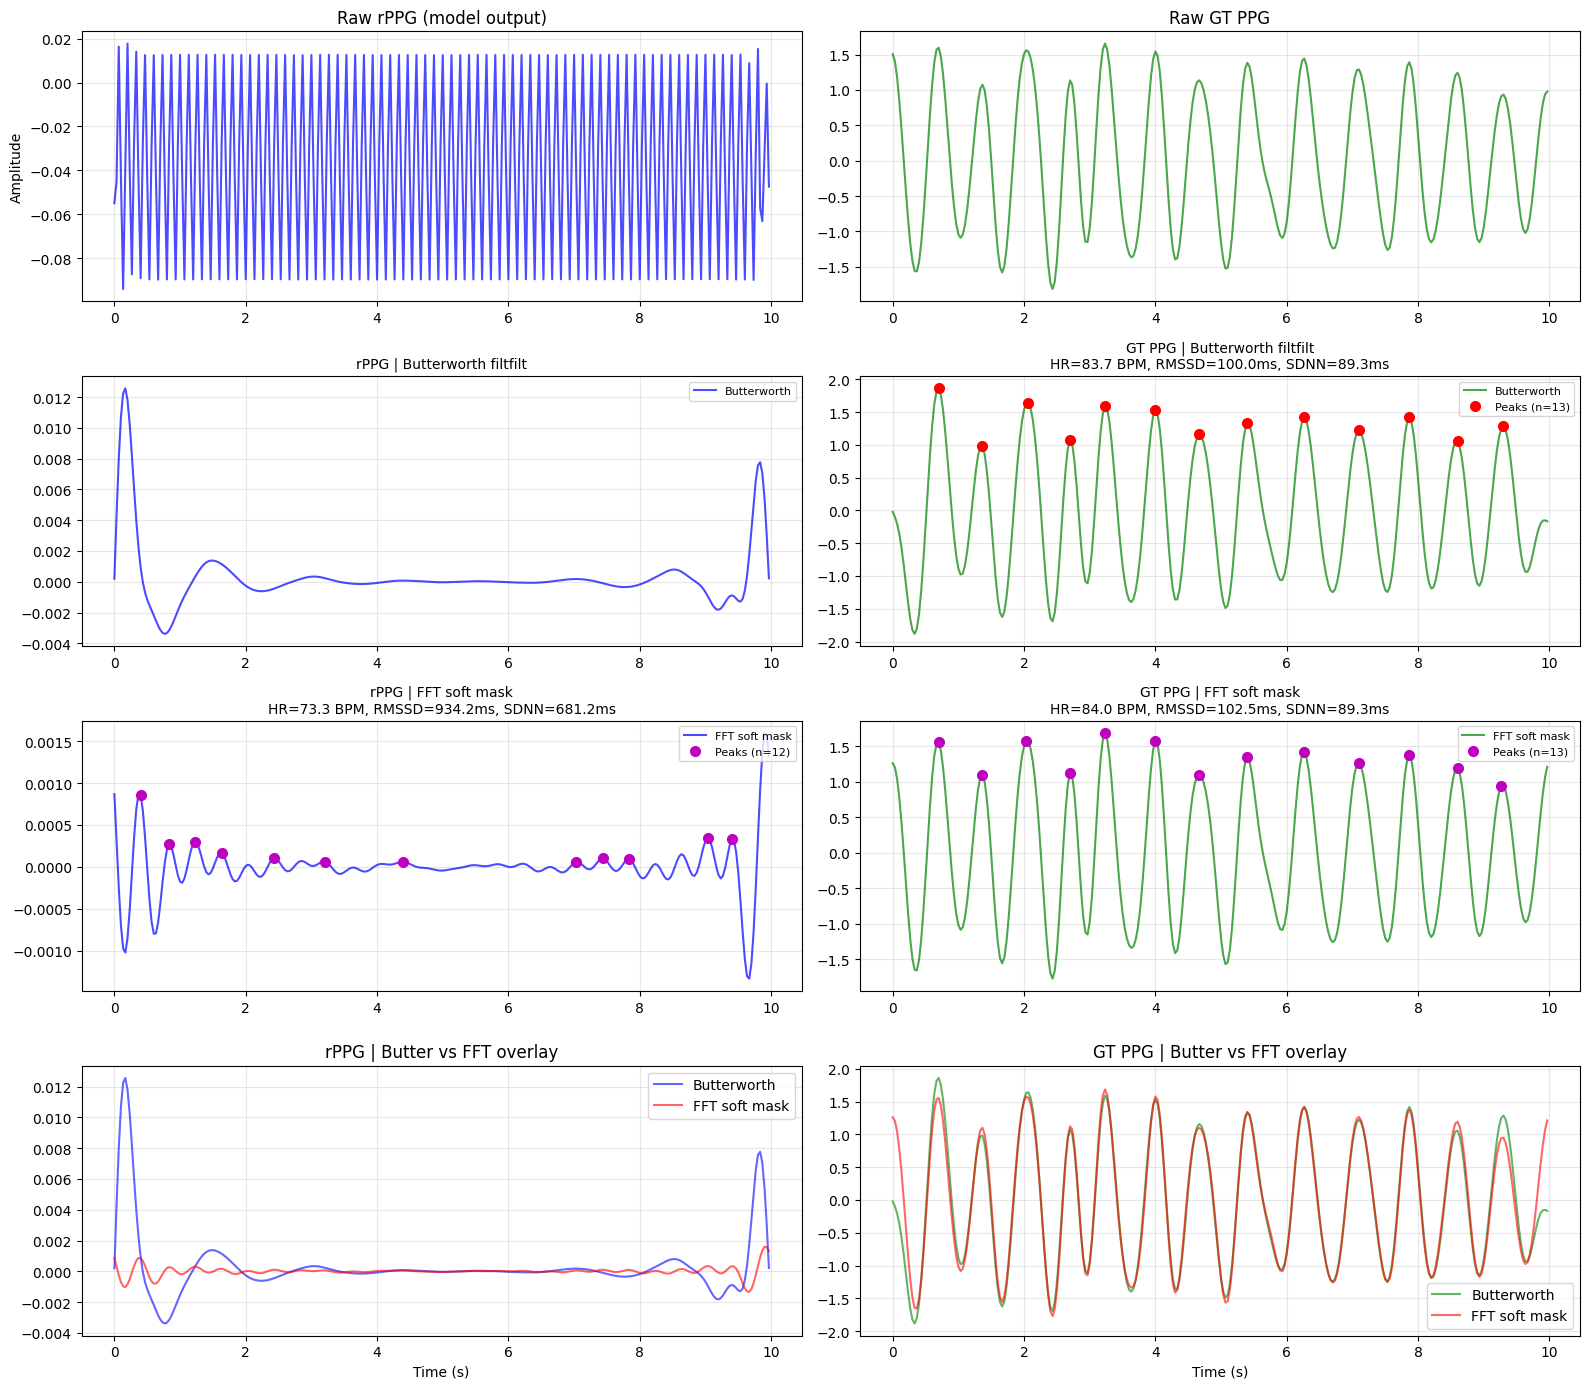

In [21]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy.signal import butter, filtfilt


# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/nirpdriving/physnet/LOSO_driving_cropped_ncorshift+kldiv/fold_8/best_model.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/driving_cropped_dl_data'
pic_save_dir ='/home/son/orientation-uv-rppg/data/pics'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 및 추론 =====

all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5') ]
valid_files = all_files[8:9]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

input_vid , gt_ppg, _ = valid_dataset[5]
input_vid = input_vid.unsqueeze(0)

# 💡 1. 데이터를 모델과 같은 디바이스(GPU)로 이동
input_vid = input_vid.to(device)

# 💡 2. 기울기 계산 방지 (추론 모드)
with torch.no_grad():
    rppg  = model(input_vid)

# 💡 3. SciPy 필터 및 시각화를 위해 CPU로 내리고 NumPy 1D 배열로 변환
rppg_np = rppg.cpu().numpy().flatten()
# ─────────────────────────────────────────────────────────────
# 1. 두 가지 bandpass
# ─────────────────────────────────────────────────────────────
def butter_bandpass_filter(data, lowcut=0.66, highcut=2.5, fs=30, order=4):
    """Zero-phase Butterworth bandpass (HRV 평가 표준)"""
    nyq = 0.5 * fs
    b, a = butter(order, [lowcut/nyq, highcut/nyq], btype='band')
    return filtfilt(b, a, data)


def bandpass_fft_soft(signal, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    """FFT soft mask bandpass (학습용, sigmoid mask)"""
    is_numpy = isinstance(signal, np.ndarray)
    if is_numpy:
        signal = torch.tensor(signal, dtype=torch.float32)
    N = signal.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(signal.device)
    fft_signal = torch.fft.rfft(signal)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    fft_filtered = fft_signal * mask
    filtered = torch.fft.irfft(fft_filtered, n=N)
    if is_numpy:
        return filtered.cpu().numpy()
    return filtered


# ─────────────────────────────────────────────────────────────
# 2. HRV 계산
# ─────────────────────────────────────────────────────────────
def compute_hrv_from_rppg(rppg_signal, fs=30):
    """Returns hrv_dict, peaks. None on failure."""
    try:
        signals, info = nk.ppg_process(rppg_signal, sampling_rate=fs)
        peaks = info['PPG_Peaks']
        
        if len(peaks) < 5:
            return None, peaks
        
        hrv = nk.hrv(peaks, sampling_rate=fs, show=False)
        
        result = {
            'mean_hr_bpm': 60000 / hrv['HRV_MeanNN'].values[0],
            'rmssd_ms':    hrv['HRV_RMSSD'].values[0],
            'sdnn_ms':     hrv['HRV_SDNN'].values[0],
            'pnn50_pct':   hrv['HRV_pNN50'].values[0],
            'lf_power':    hrv['HRV_LF'].values[0],
            'hf_power':    hrv['HRV_HF'].values[0],
            'lf_hf_ratio': hrv['HRV_LFHF'].values[0],
            'num_peaks':   len(peaks),
        }
        return result, peaks
    except Exception as e:
        print(f"⚠️ HRV failed: {e}")
        return None, []


# ─────────────────────────────────────────────────────────────
# 3. 시각화 — 4-panel 비교
# ─────────────────────────────────────────────────────────────
def visualize_filter_comparison(
    rppg_raw, gt_raw,
    rppg_butter, rppg_fft,
    gt_butter, gt_fft,
    rppg_butter_peaks, rppg_fft_peaks,
    gt_butter_peaks, gt_fft_peaks,
    rppg_butter_hrv, rppg_fft_hrv,
    gt_butter_hrv, gt_fft_hrv,
    fs=30, save_path=None
):
    fig, axes = plt.subplots(4, 2, figsize=(16, 14))
    t = np.arange(len(rppg_raw)) / fs
    
    # ── Row 0: Raw signals ────────────────────────────────────
    axes[0, 0].plot(t, rppg_raw, 'b-', alpha=0.7)
    axes[0, 0].set_title('Raw rPPG (model output)')
    axes[0, 0].set_ylabel('Amplitude')
    axes[0, 0].grid(True, alpha=0.3)
    
    axes[0, 1].plot(t, gt_raw, 'g-', alpha=0.7)
    axes[0, 1].set_title('Raw GT PPG')
    axes[0, 1].grid(True, alpha=0.3)
    
    # ── Row 1: Butterworth filtered + peaks ────────────────────
    axes[1, 0].plot(t, rppg_butter, 'b-', alpha=0.7, label='Butterworth')
    if len(rppg_butter_peaks) > 0:
        axes[1, 0].plot(rppg_butter_peaks/fs, rppg_butter[rppg_butter_peaks], 
                        'ro', markersize=7, label=f'Peaks (n={len(rppg_butter_peaks)})')
    title = 'rPPG | Butterworth filtfilt'
    if rppg_butter_hrv:
        title += f'\nHR={rppg_butter_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={rppg_butter_hrv["rmssd_ms"]:.1f}ms, SDNN={rppg_butter_hrv["sdnn_ms"]:.1f}ms'
    axes[1, 0].set_title(title, fontsize=10)
    axes[1, 0].legend(loc='upper right', fontsize=8)
    axes[1, 0].grid(True, alpha=0.3)
    
    axes[1, 1].plot(t, gt_butter, 'g-', alpha=0.7, label='Butterworth')
    if len(gt_butter_peaks) > 0:
        axes[1, 1].plot(gt_butter_peaks/fs, gt_butter[gt_butter_peaks], 
                        'ro', markersize=7, label=f'Peaks (n={len(gt_butter_peaks)})')
    title = 'GT PPG | Butterworth filtfilt'
    if gt_butter_hrv:
        title += f'\nHR={gt_butter_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={gt_butter_hrv["rmssd_ms"]:.1f}ms, SDNN={gt_butter_hrv["sdnn_ms"]:.1f}ms'
    axes[1, 1].set_title(title, fontsize=10)
    axes[1, 1].legend(loc='upper right', fontsize=8)
    axes[1, 1].grid(True, alpha=0.3)
    
    # ── Row 2: FFT soft mask filtered + peaks ──────────────────
    axes[2, 0].plot(t, rppg_fft, 'b-', alpha=0.7, label='FFT soft mask')
    if len(rppg_fft_peaks) > 0:
        axes[2, 0].plot(rppg_fft_peaks/fs, rppg_fft[rppg_fft_peaks], 
                        'mo', markersize=7, label=f'Peaks (n={len(rppg_fft_peaks)})')
    title = 'rPPG | FFT soft mask'
    if rppg_fft_hrv:
        title += f'\nHR={rppg_fft_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={rppg_fft_hrv["rmssd_ms"]:.1f}ms, SDNN={rppg_fft_hrv["sdnn_ms"]:.1f}ms'
    axes[2, 0].set_title(title, fontsize=10)
    axes[2, 0].legend(loc='upper right', fontsize=8)
    axes[2, 0].grid(True, alpha=0.3)
    
    axes[2, 1].plot(t, gt_fft, 'g-', alpha=0.7, label='FFT soft mask')
    if len(gt_fft_peaks) > 0:
        axes[2, 1].plot(gt_fft_peaks/fs, gt_fft[gt_fft_peaks], 
                        'mo', markersize=7, label=f'Peaks (n={len(gt_fft_peaks)})')
    title = 'GT PPG | FFT soft mask'
    if gt_fft_hrv:
        title += f'\nHR={gt_fft_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={gt_fft_hrv["rmssd_ms"]:.1f}ms, SDNN={gt_fft_hrv["sdnn_ms"]:.1f}ms'
    axes[2, 1].set_title(title, fontsize=10)
    axes[2, 1].legend(loc='upper right', fontsize=8)
    axes[2, 1].grid(True, alpha=0.3)
    
    # ── Row 3: Filter overlay (Butter vs FFT) — 비교 ────────────
    axes[3, 0].plot(t, rppg_butter, 'b-', alpha=0.6, label='Butterworth')
    axes[3, 0].plot(t, rppg_fft, 'r-', alpha=0.6, label='FFT soft mask')
    axes[3, 0].set_title('rPPG | Butter vs FFT overlay')
    axes[3, 0].set_xlabel('Time (s)')
    axes[3, 0].legend()
    axes[3, 0].grid(True, alpha=0.3)
    
    axes[3, 1].plot(t, gt_butter, 'g-', alpha=0.6, label='Butterworth')
    axes[3, 1].plot(t, gt_fft, 'r-', alpha=0.6, label='FFT soft mask')
    axes[3, 1].set_title('GT PPG | Butter vs FFT overlay')
    axes[3, 1].set_xlabel('Time (s)')
    axes[3, 1].legend()
    axes[3, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
        print(f"\n💾 Saved: {save_path}")
    plt.show()


# ─────────────────────────────────────────────────────────────
# 4. 본 비교 실행 (본인 변수 그대로 사용)
# ─────────────────────────────────────────────────────────────
"""
가지고 있는 변수:
  - rppg_np: 모델 출력 (900,) numpy
  - gt_ppg:  GT (tensor or numpy)
"""

gt_ppg_np = gt_ppg.numpy() if hasattr(gt_ppg, 'numpy') else np.asarray(gt_ppg)

# Filter 적용
rppg_butter = butter_bandpass_filter(rppg_np, fs=30)
rppg_fft    = bandpass_fft_soft(rppg_np, fs=30)
gt_butter   = butter_bandpass_filter(gt_ppg_np, fs=30)
gt_fft      = bandpass_fft_soft(gt_ppg_np, fs=30)

# HRV 계산 (4 케이스)
print("="*60)
print("Computing HRV for 4 conditions...")
print("="*60)

rppg_butter_hrv, rppg_butter_peaks = compute_hrv_from_rppg(rppg_butter)
rppg_fft_hrv,    rppg_fft_peaks    = compute_hrv_from_rppg(rppg_fft)
gt_butter_hrv,   gt_butter_peaks   = compute_hrv_from_rppg(gt_butter)
gt_fft_hrv,      gt_fft_peaks      = compute_hrv_from_rppg(gt_fft)


# ─────────────────────────────────────────────────────────────
# 5. 결과 표 출력
# ─────────────────────────────────────────────────────────────
def print_hrv_table(rppg_b, rppg_f, gt_b, gt_f):
    print("\n" + "="*80)
    print(f"{'Feature':<15} {'GT(Butter)':<12} {'GT(FFT)':<12} {'rPPG(Butter)':<14} {'rPPG(FFT)':<12}")
    print("-"*80)
    
    features = [
        ('HR (BPM)',    'mean_hr_bpm'),
        ('RMSSD (ms)',  'rmssd_ms'),
        ('SDNN (ms)',   'sdnn_ms'),
        ('pNN50 (%)',   'pnn50_pct'),
        ('LF',          'lf_power'),
        ('HF',          'hf_power'),
        ('LF/HF',       'lf_hf_ratio'),
        ('# peaks',     'num_peaks'),
    ]
    
    for label, key in features:
        gt_b_val = f"{gt_b[key]:.2f}" if gt_b else "N/A"
        gt_f_val = f"{gt_f[key]:.2f}" if gt_f else "N/A"
        rp_b_val = f"{rppg_b[key]:.2f}" if rppg_b else "N/A"
        rp_f_val = f"{rppg_f[key]:.2f}" if rppg_f else "N/A"
        print(f"{label:<15} {gt_b_val:<12} {gt_f_val:<12} {rp_b_val:<14} {rp_f_val:<12}")
    
    # MAE rPPG vs GT
    print("-"*80)
    print(f"{'MAE rPPG vs GT':<40}")
    if rppg_b and gt_b:
        print(f"  [Butterworth]  HR={abs(rppg_b['mean_hr_bpm']-gt_b['mean_hr_bpm']):.2f} BPM, "
              f"RMSSD={abs(rppg_b['rmssd_ms']-gt_b['rmssd_ms']):.2f} ms, "
              f"SDNN={abs(rppg_b['sdnn_ms']-gt_b['sdnn_ms']):.2f} ms")
    if rppg_f and gt_f:
        print(f"  [FFT soft]     HR={abs(rppg_f['mean_hr_bpm']-gt_f['mean_hr_bpm']):.2f} BPM, "
              f"RMSSD={abs(rppg_f['rmssd_ms']-gt_f['rmssd_ms']):.2f} ms, "
              f"SDNN={abs(rppg_f['sdnn_ms']-gt_f['sdnn_ms']):.2f} ms")
    
    # 두 filter 간 차이 (같은 신호 기준)
    print("-"*80)
    print(f"{'Filter 간 차이 (Butter - FFT)':<40}")
    if rppg_b and rppg_f:
        print(f"  rPPG:  ΔHR={rppg_b['mean_hr_bpm']-rppg_f['mean_hr_bpm']:+.2f}, "
              f"ΔRMSSD={rppg_b['rmssd_ms']-rppg_f['rmssd_ms']:+.2f}, "
              f"ΔSDNN={rppg_b['sdnn_ms']-rppg_f['sdnn_ms']:+.2f}")
    if gt_b and gt_f:
        print(f"  GT:    ΔHR={gt_b['mean_hr_bpm']-gt_f['mean_hr_bpm']:+.2f}, "
              f"ΔRMSSD={gt_b['rmssd_ms']-gt_f['rmssd_ms']:+.2f}, "
              f"ΔSDNN={gt_b['sdnn_ms']-gt_f['sdnn_ms']:+.2f}")
    print("="*80)

print_hrv_table(rppg_butter_hrv, rppg_fft_hrv, gt_butter_hrv, gt_fft_hrv)


# ─────────────────────────────────────────────────────────────
# 6. 시각화
# ─────────────────────────────────────────────────────────────
visualize_filter_comparison(
    rppg_raw=rppg_np, gt_raw=gt_ppg_np,
    rppg_butter=rppg_butter, rppg_fft=rppg_fft,
    gt_butter=gt_butter,     gt_fft=gt_fft,
    rppg_butter_peaks=rppg_butter_peaks, rppg_fft_peaks=rppg_fft_peaks,
    gt_butter_peaks=gt_butter_peaks,     gt_fft_peaks=gt_fft_peaks,
    rppg_butter_hrv=rppg_butter_hrv, rppg_fft_hrv=rppg_fft_hrv,
    gt_butter_hrv=gt_butter_hrv,     gt_fft_hrv=gt_fft_hrv,
    fs=30,
    save_path=os.path.join(pic_save_dir, 'hrv_filter_comparison.png'),
)

모델 로드 완료
['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped_len300/final_dataset_C001_20250701.h5']
rPPG: (900,), GT: (900,)
Computing HRV for 4 conditions...
(GT는 이미 bandpass+znorm 적용됨 → 추가 필터 없이 동일 신호 사용)

Feature         GT           GT(=)        rPPG(Butter)   rPPG(FFT)   
--------------------------------------------------------------------------------
HR (BPM)        53.25        53.25        66.59          69.15       
RMSSD (ms)      103.19       103.19       276.69         243.98      
SDNN (ms)       73.91        73.91        194.65         183.58      
pNN50 (%)       58.33        58.33        90.00          84.85       
LF              0.83         0.83         1.04           1.29        
HF              3.01         3.01         1.84           0.99        
LF/HF           0.28         0.28         0.57           1.31        
# peaks         26.00        26.00        32.00          35.00       
-----------------

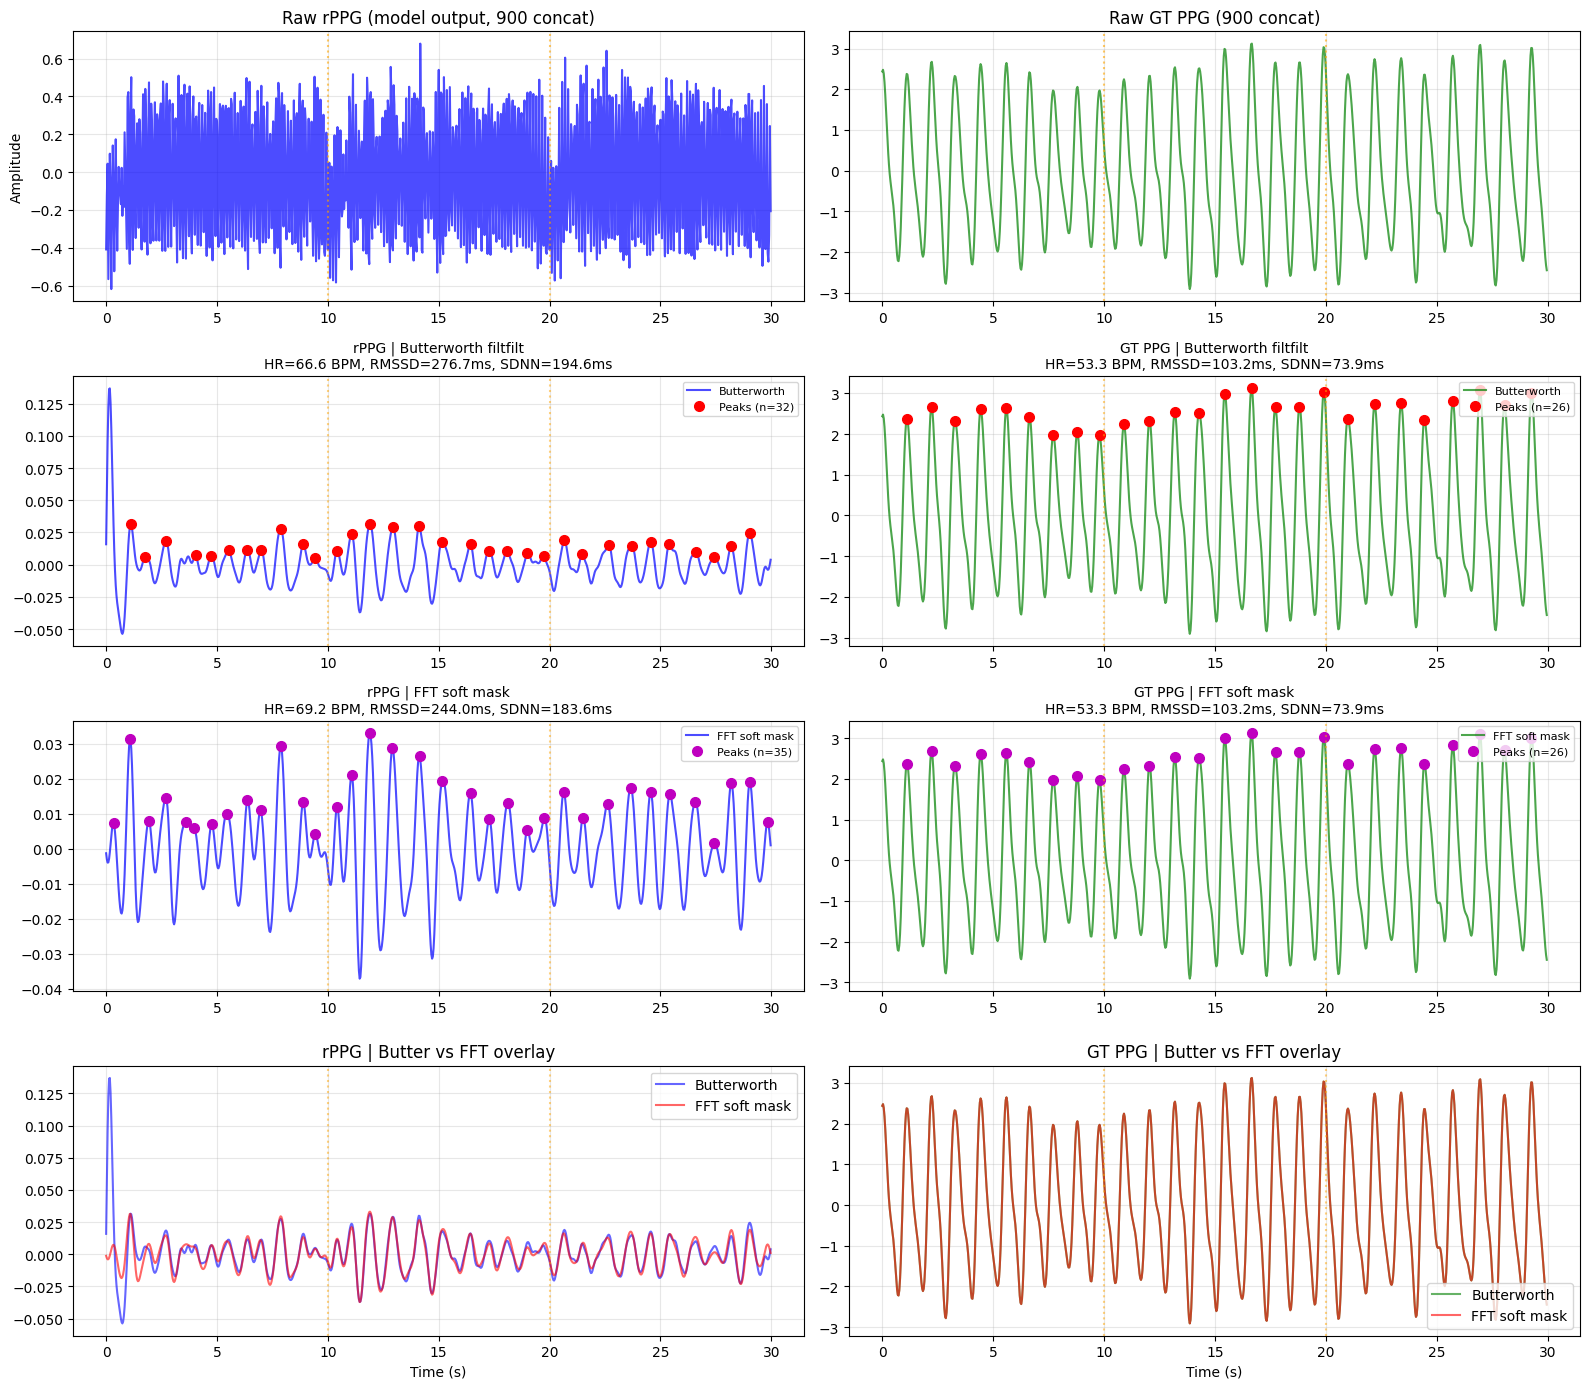

In [23]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy.signal import butter, filtfilt, find_peaks
from astropy.timeseries import LombScargle


# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/300franewithoutregis/klloss+ncorshift/0.0001_epoch:79_MAE: 10.00.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped_len300'
pic_save_dir = '/home/son/orientation-uv-rppg/data/pics'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")


# ===== 데이터 로드 및 추론 (300×3 → concat 900) =====
all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5')]
valid_files = all_files[12:13]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

GROUP = 3
group_idx = 5   # 몇 번째 900 그룹을 볼지 (= 원래 윈도우 인덱스 15,16,17 묶음)

s = group_idx * GROUP
rppg_parts, gt_parts = [], []
for i in range(s, s + GROUP):
    input_vid, gt_ppg, _ = valid_dataset[i]
    input_vid = input_vid.unsqueeze(0).to(device)   # (1,1,300,64,64)
    with torch.no_grad():
        rppg = model(input_vid)
    rppg_parts.append(rppg.cpu().numpy().flatten().astype(np.float64))   # (300,)
    gt_np = gt_ppg.numpy() if hasattr(gt_ppg, 'numpy') else np.asarray(gt_ppg)
    gt_parts.append(gt_np.astype(np.float64))                            # (300,)

rppg_np   = np.concatenate(rppg_parts)   # (900,)
gt_ppg_np = np.concatenate(gt_parts)     # (900,)
print(f"rPPG: {rppg_np.shape}, GT: {gt_ppg_np.shape}")


# ─────────────────────────────────────────────────────────────
# 1. 두 가지 bandpass
# ─────────────────────────────────────────────────────────────
def butter_bandpass_filter(data, lowcut=0.66, highcut=2.5, fs=30, order=4):
    nyq = 0.5 * fs
    b, a = butter(order, [lowcut/nyq, highcut/nyq], btype='band')
    return filtfilt(b, a, data)


def bandpass_fft_soft(signal, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(signal, np.ndarray)
    if is_numpy:
        signal = torch.tensor(signal, dtype=torch.float32)
    N = signal.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(signal.device)
    fft_signal = torch.fft.rfft(signal)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    filtered = torch.fft.irfft(fft_signal * mask, n=N)
    return filtered.cpu().numpy() if is_numpy else filtered


# ─────────────────────────────────────────────────────────────
# 2. HRV 계산 — Contrast-Phys+ 방식 (Lomb-Scargle)
# ─────────────────────────────────────────────────────────────
def compute_hrv_from_rppg(sig, fs=30):
    """Returns hrv_dict, peaks. None on failure. Contrast-Phys+ 호환."""
    try:
        clean = nk.ppg_clean(sig.copy(), sampling_rate=fs, method='elgendi')
        peaks = nk.ppg_findpeaks(clean, sampling_rate=fs)["PPG_Peaks"]
        if len(peaks) < 5:
            return None, peaks

        ibi = (peaks[1:] - peaks[:-1]) / fs   # 초
        ibi_ms = ibi * 1000
        d = np.diff(ibi_ms)

        # time-domain
        mean_hr = 60000.0 / np.mean(ibi_ms)
        sdnn    = np.std(ibi_ms, ddof=1)
        rmssd   = np.sqrt(np.mean(d**2))
        pnn50   = np.mean(np.abs(d) > 50) * 100

        # freq-domain (Lomb-Scargle)
        def find_highest_peak(spec):
            pl = find_peaks(spec)[0]
            return np.argmax(spec) if len(pl) == 0 else pl[np.argmax(spec[pl])]

        lf_power = hf_power = lf_hf = np.nan
        if len(ibi) >= 4:
            freq, power = LombScargle(np.cumsum(ibi), ibi).autopower(
                minimum_frequency=0.01, maximum_frequency=0.51)
            idx_lf = np.where((freq > 0.04) & (freq < 0.15))[0]
            idx_hf = np.where((freq > 0.15) & (freq < 0.40))[0]
            if len(idx_lf) > 0 and len(idx_hf) > 0:
                lf_power = np.sum(power[idx_lf])
                hf_power = np.sum(power[idx_hf])
                if hf_power > 0:
                    lf_hf = lf_power / hf_power

        result = {
            'mean_hr_bpm': mean_hr,
            'rmssd_ms':    rmssd,
            'sdnn_ms':     sdnn,
            'pnn50_pct':   pnn50,
            'lf_power':    lf_power,
            'hf_power':    hf_power,
            'lf_hf_ratio': lf_hf,
            'num_peaks':   len(peaks),
        }
        return result, peaks
    except Exception as e:
        print(f"⚠️ HRV failed: {e}")
        return None, np.array([])


# ─────────────────────────────────────────────────────────────
# 3. 시각화 — 4-panel 비교 (원본과 동일 레이아웃)
# ─────────────────────────────────────────────────────────────
def visualize_filter_comparison(
    rppg_raw, gt_raw,
    rppg_butter, rppg_fft,
    gt_butter, gt_fft,
    rppg_butter_peaks, rppg_fft_peaks,
    gt_butter_peaks, gt_fft_peaks,
    rppg_butter_hrv, rppg_fft_hrv,
    gt_butter_hrv, gt_fft_hrv,
    fs=30, save_path=None
):
    fig, axes = plt.subplots(4, 2, figsize=(16, 14))
    t = np.arange(len(rppg_raw)) / fs

    # 윈도우 경계 표시선 (300, 600 프레임 = 10s, 20s)
    boundaries = [300/fs, 600/fs]

    # Row 0: Raw
    axes[0, 0].plot(t, rppg_raw, 'b-', alpha=0.7)
    axes[0, 0].set_title('Raw rPPG (model output, 900 concat)')
    axes[0, 0].set_ylabel('Amplitude'); axes[0, 0].grid(True, alpha=0.3)
    axes[0, 1].plot(t, gt_raw, 'g-', alpha=0.7)
    axes[0, 1].set_title('Raw GT PPG (900 concat)')
    axes[0, 1].grid(True, alpha=0.3)
    for ax in [axes[0,0], axes[0,1]]:
        for bx in boundaries:
            ax.axvline(bx, color='orange', ls=':', alpha=0.6)

    # Row 1: Butterworth + peaks
    axes[1, 0].plot(t, rppg_butter, 'b-', alpha=0.7, label='Butterworth')
    if len(rppg_butter_peaks) > 0:
        axes[1, 0].plot(rppg_butter_peaks/fs, rppg_butter[rppg_butter_peaks],
                        'ro', markersize=7, label=f'Peaks (n={len(rppg_butter_peaks)})')
    title = 'rPPG | Butterworth filtfilt'
    if rppg_butter_hrv:
        title += f'\nHR={rppg_butter_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={rppg_butter_hrv["rmssd_ms"]:.1f}ms, SDNN={rppg_butter_hrv["sdnn_ms"]:.1f}ms'
    axes[1, 0].set_title(title, fontsize=10)
    axes[1, 0].legend(loc='upper right', fontsize=8); axes[1, 0].grid(True, alpha=0.3)

    axes[1, 1].plot(t, gt_butter, 'g-', alpha=0.7, label='Butterworth')
    if len(gt_butter_peaks) > 0:
        axes[1, 1].plot(gt_butter_peaks/fs, gt_butter[gt_butter_peaks],
                        'ro', markersize=7, label=f'Peaks (n={len(gt_butter_peaks)})')
    title = 'GT PPG | Butterworth filtfilt'
    if gt_butter_hrv:
        title += f'\nHR={gt_butter_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={gt_butter_hrv["rmssd_ms"]:.1f}ms, SDNN={gt_butter_hrv["sdnn_ms"]:.1f}ms'
    axes[1, 1].set_title(title, fontsize=10)
    axes[1, 1].legend(loc='upper right', fontsize=8); axes[1, 1].grid(True, alpha=0.3)

    # Row 2: FFT soft mask + peaks
    axes[2, 0].plot(t, rppg_fft, 'b-', alpha=0.7, label='FFT soft mask')
    if len(rppg_fft_peaks) > 0:
        axes[2, 0].plot(rppg_fft_peaks/fs, rppg_fft[rppg_fft_peaks],
                        'mo', markersize=7, label=f'Peaks (n={len(rppg_fft_peaks)})')
    title = 'rPPG | FFT soft mask'
    if rppg_fft_hrv:
        title += f'\nHR={rppg_fft_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={rppg_fft_hrv["rmssd_ms"]:.1f}ms, SDNN={rppg_fft_hrv["sdnn_ms"]:.1f}ms'
    axes[2, 0].set_title(title, fontsize=10)
    axes[2, 0].legend(loc='upper right', fontsize=8); axes[2, 0].grid(True, alpha=0.3)

    axes[2, 1].plot(t, gt_fft, 'g-', alpha=0.7, label='FFT soft mask')
    if len(gt_fft_peaks) > 0:
        axes[2, 1].plot(gt_fft_peaks/fs, gt_fft[gt_fft_peaks],
                        'mo', markersize=7, label=f'Peaks (n={len(gt_fft_peaks)})')
    title = 'GT PPG | FFT soft mask'
    if gt_fft_hrv:
        title += f'\nHR={gt_fft_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={gt_fft_hrv["rmssd_ms"]:.1f}ms, SDNN={gt_fft_hrv["sdnn_ms"]:.1f}ms'
    axes[2, 1].set_title(title, fontsize=10)
    axes[2, 1].legend(loc='upper right', fontsize=8); axes[2, 1].grid(True, alpha=0.3)

    # Row 3: overlay
    axes[3, 0].plot(t, rppg_butter, 'b-', alpha=0.6, label='Butterworth')
    axes[3, 0].plot(t, rppg_fft, 'r-', alpha=0.6, label='FFT soft mask')
    axes[3, 0].set_title('rPPG | Butter vs FFT overlay')
    axes[3, 0].set_xlabel('Time (s)'); axes[3, 0].legend(); axes[3, 0].grid(True, alpha=0.3)

    axes[3, 1].plot(t, gt_butter, 'g-', alpha=0.6, label='Butterworth')
    axes[3, 1].plot(t, gt_fft, 'r-', alpha=0.6, label='FFT soft mask')
    axes[3, 1].set_title('GT PPG | Butter vs FFT overlay')
    axes[3, 1].set_xlabel('Time (s)'); axes[3, 1].legend(); axes[3, 1].grid(True, alpha=0.3)

    for bx in boundaries:
        for r in range(1, 4):
            axes[r, 0].axvline(bx, color='orange', ls=':', alpha=0.5)
            axes[r, 1].axvline(bx, color='orange', ls=':', alpha=0.5)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
        print(f"\n💾 Saved: {save_path}")
    plt.show()


# ─────────────────────────────────────────────────────────────
# 4. 필터 적용 — GT는 추가 bandpass 안 함 (이미 필터+znorm)
# ─────────────────────────────────────────────────────────────
rppg_butter = butter_bandpass_filter(rppg_np, fs=30)
rppg_fft    = bandpass_fft_soft(rppg_np, fs=30)
gt_butter   = gt_ppg_np.copy()   # GT: 추가 필터 X
gt_fft      = gt_ppg_np.copy()   # GT: 추가 필터 X

print("="*60)
print("Computing HRV for 4 conditions...")
print("(GT는 이미 bandpass+znorm 적용됨 → 추가 필터 없이 동일 신호 사용)")
print("="*60)

rppg_butter_hrv, rppg_butter_peaks = compute_hrv_from_rppg(rppg_butter)
rppg_fft_hrv,    rppg_fft_peaks    = compute_hrv_from_rppg(rppg_fft)
gt_butter_hrv,   gt_butter_peaks   = compute_hrv_from_rppg(gt_butter)
gt_fft_hrv,      gt_fft_peaks       = compute_hrv_from_rppg(gt_fft)


# ─────────────────────────────────────────────────────────────
# 5. 결과 표 (원본과 동일)
# ─────────────────────────────────────────────────────────────
def print_hrv_table(rppg_b, rppg_f, gt_b, gt_f):
    print("\n" + "="*80)
    print(f"{'Feature':<15} {'GT':<12} {'GT(=)':<12} {'rPPG(Butter)':<14} {'rPPG(FFT)':<12}")
    print("-"*80)
    features = [('HR (BPM)','mean_hr_bpm'), ('RMSSD (ms)','rmssd_ms'),
                ('SDNN (ms)','sdnn_ms'), ('pNN50 (%)','pnn50_pct'),
                ('LF','lf_power'), ('HF','hf_power'),
                ('LF/HF','lf_hf_ratio'), ('# peaks','num_peaks')]
    for label, key in features:
        g_b = f"{gt_b[key]:.2f}" if gt_b else "N/A"
        g_f = f"{gt_f[key]:.2f}" if gt_f else "N/A"
        r_b = f"{rppg_b[key]:.2f}" if rppg_b else "N/A"
        r_f = f"{rppg_f[key]:.2f}" if rppg_f else "N/A"
        print(f"{label:<15} {g_b:<12} {g_f:<12} {r_b:<14} {r_f:<12}")
    print("-"*80)
    print("MAE rPPG vs GT")
    if rppg_b and gt_b:
        print(f"  [Butter→GT] HR={abs(rppg_b['mean_hr_bpm']-gt_b['mean_hr_bpm']):.2f}, "
              f"RMSSD={abs(rppg_b['rmssd_ms']-gt_b['rmssd_ms']):.2f}, "
              f"SDNN={abs(rppg_b['sdnn_ms']-gt_b['sdnn_ms']):.2f}")
    if rppg_f and gt_f:
        print(f"  [FFT→GT]    HR={abs(rppg_f['mean_hr_bpm']-gt_f['mean_hr_bpm']):.2f}, "
              f"RMSSD={abs(rppg_f['rmssd_ms']-gt_f['rmssd_ms']):.2f}, "
              f"SDNN={abs(rppg_f['sdnn_ms']-gt_f['sdnn_ms']):.2f}")
    print("="*80)

print_hrv_table(rppg_butter_hrv, rppg_fft_hrv, gt_butter_hrv, gt_fft_hrv)


# ─────────────────────────────────────────────────────────────
# 6. 시각화
# ─────────────────────────────────────────────────────────────
visualize_filter_comparison(
    rppg_raw=rppg_np, gt_raw=gt_ppg_np,
    rppg_butter=rppg_butter, rppg_fft=rppg_fft,
    gt_butter=gt_butter, gt_fft=gt_fft,
    rppg_butter_peaks=rppg_butter_peaks, rppg_fft_peaks=rppg_fft_peaks,
    gt_butter_peaks=gt_butter_peaks, gt_fft_peaks=gt_fft_peaks,
    rppg_butter_hrv=rppg_butter_hrv, rppg_fft_hrv=rppg_fft_hrv,
    gt_butter_hrv=gt_butter_hrv, gt_fft_hrv=gt_fft_hrv,
    fs=30,
    save_path=os.path.join(pic_save_dir, 'hrv_filter_comparison_900.png'),
)

In [19]:
#physnet hrv

import os
import numpy as np
import torch
from tqdm import tqdm
from scipy.signal import find_peaks, butter, filtfilt
from astropy.timeseries import LombScargle
from scipy.stats import pearsonr
import neurokit2 as nk


# ============================================================
# 1. 설정 + 모델 로드
# ============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/300franewithregis_13out_and_znorm/bandpassbeforelosscompute_negcorloss/physent_data_wo_ol_lr:0.0006000000000000001_epoch:48_MAE: 12.71.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")

all_files = sorted([os.path.join(data_dir, u)
                    for u in os.listdir(data_dir) if u.endswith('.h5')])
valid_files = all_files[12:]
valid_dataset = rPPGDataset(valid_files)
print(f"파일 {len(valid_files)}개, 총 윈도우 {len(valid_dataset)}개")


# ============================================================
# 2. HRV 추출 함수 (Contrast-Phys+ 호환 + time-domain 추가)
# ============================================================
def butter_bandpass_filter(data, lowcut=0.66, highcut=2.5, fs=30, order=4):
    nyq = 0.5 * fs
    b, a = butter(order, [lowcut/nyq, highcut/nyq], btype='band')
    return filtfilt(b, a, data)


def get_ibi(sig, fps=30):
    """Contrast-Phys+ 원본. IBI 단위는 초."""
    try:
        ppg_clean = nk.ppg_clean(sig.copy(), sampling_rate=fps, method='elgendi')
        info = nk.ppg_findpeaks(ppg_clean, sampling_rate=fps)
        peak_loc = info["PPG_Peaks"]
        if len(peak_loc) < 5:
            return None, peak_loc
        ibi = (peak_loc[1:] - peak_loc[:-1]) / fps   # 초
        return ibi, peak_loc
    except Exception as e:
        return None, np.array([])


def freq_features(ibi):
    """Lomb-Scargle 기반 LF/HF. Contrast-Phys+ 원본 + 안전장치."""
    if len(ibi) < 4:
        return None
    
    def find_highest_peak(sig):
        peak_loc = find_peaks(sig)[0]
        if len(peak_loc) == 0:
            return np.argmax(sig)
        return peak_loc[np.argmax(sig[peak_loc])]
    
    freq, power = LombScargle(np.cumsum(ibi), ibi).autopower(
        minimum_frequency=0.01, maximum_frequency=0.51
    )
    idx_lf = np.where((freq > 0.04) & (freq < 0.15))[0]
    idx_hf = np.where((freq > 0.15) & (freq < 0.40))[0]
    if len(idx_lf) == 0 or len(idx_hf) == 0:
        return None
    
    power_lf = np.sum(power[idx_lf])
    power_hf = np.sum(power[idx_hf])
    if power_hf == 0:
        return None
    
    return {
        'lf_f':  freq[idx_lf][find_highest_peak(power[idx_lf])],
        'hf_f':  freq[idx_hf][find_highest_peak(power[idx_hf])],
        'lfnu':  power_lf / (power_lf + power_hf),
        'hfnu':  power_hf / (power_lf + power_hf),
        'lf_hf': power_lf / power_hf,
    }


def time_features(ibi):
    """Time-domain HRV. IBI 입력은 초, 출력은 ms."""
    if len(ibi) < 3:
        return None
    ibi_ms = ibi * 1000
    diff = np.diff(ibi_ms)
    return {
        'mean_hr': 60000.0 / np.mean(ibi_ms),
        'sdnn':    np.std(ibi_ms, ddof=1),
        'rmssd':   np.sqrt(np.mean(diff**2)),
        'pnn50':   np.mean(np.abs(diff) > 50) * 100,
    }


def compute_all_hrv(sig, fps=30, use_bandpass=True):
    """한 윈도우에 대한 통합 HRV (time + freq)."""
    if use_bandpass:
        sig = butter_bandpass_filter(sig, fs=fps)
    
    ibi, peaks = get_ibi(sig, fps)
    if ibi is None:
        return None
    
    result = {'num_peaks': len(peaks)}
    tf = time_features(ibi)
    ff = freq_features(ibi)
    if tf is None or ff is None:
        return None
    result.update(tf)
    result.update(ff)
    return result


# ============================================================
# 3. 전체 윈도우 평가 루프
# ============================================================
results = []
USE_BANDPASS = True  # Contrast-Phys+ 그대로 = False. raw 품질 낮으면 True 시도

for i in tqdm(range(len(valid_dataset)), desc="HRV"):
    input_vid, gt_ppg, _ = valid_dataset[i]
    input_vid = input_vid.unsqueeze(0).to(device)
    
    with torch.no_grad():
        rppg = model(input_vid)
    
    rppg_np   = rppg.cpu().numpy().flatten().astype(np.float64)
    gt_ppg_np = (gt_ppg.numpy() if hasattr(gt_ppg, 'numpy')
                 else np.asarray(gt_ppg)).astype(np.float64)
    
    r_pred = compute_all_hrv(rppg_np,   fps=30, use_bandpass=USE_BANDPASS)
    r_gt   = compute_all_hrv(gt_ppg_np, fps=30, use_bandpass=USE_BANDPASS)
    
    results.append({'pred': r_pred, 'gt': r_gt})


# ============================================================
# 4. 페어드 메트릭 (Contrast-Phys+ Table 2 호환: STD / RMSE / R + MAE)
# ============================================================
def paired_metrics(metric_key):
    pairs = [(r['pred'][metric_key], r['gt'][metric_key])
             for r in results
             if r['pred'] is not None and r['gt'] is not None
             and metric_key in r['pred'] and metric_key in r['gt']
             and np.isfinite(r['pred'][metric_key])
             and np.isfinite(r['gt'][metric_key])]
    if len(pairs) < 2:
        return None
    pred = np.array([p for p, _ in pairs])
    gt   = np.array([g for _, g in pairs])
    err  = pred - gt
    return {
        'pred_mean': pred.mean(),
        'gt_mean':   gt.mean(),
        'MAE':       np.mean(np.abs(err)),
        'STD':       np.std(err, ddof=1),
        'RMSE':      np.sqrt(np.mean(err**2)),
        'R':         pearsonr(pred, gt)[0] if np.std(pred) > 0 and np.std(gt) > 0 else np.nan,
        'n':         len(pairs),
    }


# ============================================================
# 5. 결과 출력 — 두 가지 표
# ============================================================

# ───── 표 1: Contrast-Phys+ Table 2 직접 비교용 ─────
print("\n" + "="*78)
print("[표 1] Contrast-Phys+ Table 2 직접 비교 (UBFC-rPPG → CNA 본인 결과)")
print("="*78)
print(f"{'Metric':<14}{'STD':<10}{'RMSE':<10}{'MAE':<10}{'R':<10}{'n':<6}")
print("-"*78)
for label, key in [('LF (n.u.)',  'lfnu'),
                   ('HF (n.u.)',  'hfnu'),
                   ('LF/HF',      'lf_hf'),
                   ('RF (Hz)',    'hf_f')]:
    m = paired_metrics(key)
    if m:
        print(f"{label:<14}{m['STD']:<10.3f}{m['RMSE']:<10.3f}"
              f"{m['MAE']:<10.3f}{m['R']:<10.3f}{m['n']:<6}")
    else:
        print(f"{label:<14}{'N/A':<10}")





# ───── 표 2: Sleep stage 분류용 time-domain HRV ─────
print("\n" + "="*78)
print("[표 2] Time-domain HRV (Sleep stage 분류용)")
print("="*78)
print(f"{'Metric':<14}{'pred_mean':<12}{'gt_mean':<12}"
      f"{'MAE':<10}{'RMSE':<10}{'R':<10}{'n':<6}")
print("-"*78)
for label, key in [('HR (BPM)',   'mean_hr'),
                   ('RMSSD (ms)', 'rmssd'),
                   ('SDNN (ms)',  'sdnn'),
                   ('pNN50 (%)',  'pnn50')]:
    m = paired_metrics(key)
    if m:
        print(f"{label:<14}{m['pred_mean']:<12.2f}{m['gt_mean']:<12.2f}"
              f"{m['MAE']:<10.2f}{m['RMSE']:<10.2f}{m['R']:<10.3f}{m['n']:<6}")
    else:
        print(f"{label:<14}{'N/A':<10}")

# 참고: Sleep stage 분류 가능 임계
print("-"*78)
print("[참고] Sleep stage 분류 가능선 (이전 대화 정리):")
print(f"  HR MAE ≤ 3 BPM,  RMSSD MAE ≤ 10 ms,  SDNN MAE ≤ 10~15 ms")


# ───── 윈도우 통계 ─────
n_total = len(results)
n_valid = sum(1 for r in results if r['pred'] is not None and r['gt'] is not None)
n_pred_fail = sum(1 for r in results if r['pred'] is None)
n_gt_fail   = sum(1 for r in results if r['gt']   is None)

print("\n" + "="*78)
print(f"전체 윈도우: {n_total}")
print(f"  유효 페어:    {n_valid} ({100*n_valid/n_total:.1f}%)")
print(f"  rPPG 실패:    {n_pred_fail}")
print(f"  GT 실패:      {n_gt_fail}")
print("="*78)

모델 로드 완료
파일 4개, 총 윈도우 340개


HRV: 100%|██████████| 340/340 [04:17<00:00,  1.32it/s]


[표 1] Contrast-Phys+ Table 2 직접 비교 (UBFC-rPPG → CNA 본인 결과)
Metric        STD       RMSE      MAE       R         n     
------------------------------------------------------------------------------
LF (n.u.)     0.219     0.222     0.172     -0.011    236   
HF (n.u.)     0.219     0.222     0.172     -0.011    236   
LF/HF         1.135     1.191     0.622     -0.055    236   
RF (Hz)       0.082     0.083     0.068     -0.077    236   

[표 2] Time-domain HRV (Sleep stage 분류용)
Metric        pred_mean   gt_mean     MAE       RMSE      R         n     
------------------------------------------------------------------------------
HR (BPM)      21.52       60.41       39.60     42.88     0.108     236   
RMSSD (ms)    8061.13     72.53       7988.60   10490.05  -0.102    236   
SDNN (ms)     5404.37     65.46       5338.91   6801.73   -0.205    236   
pNN50 (%)     95.47       42.74       52.90     56.70     -0.055    236   
-------------------------------------------------------------